In [1]:
%load_ext autoreload
%autoreload 2
%aimport
%matplotlib inline

Modules to reload:
all-except-skipped

Modules to skip:



In [2]:
import os
import sys
nb_dir = os.path.dirname(os.path.split(os.getcwd())[0])
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [3]:
from tqdm import tqdm_notebook as tqdm
import pandas as pd
from turicreate import SFrame, load_sframe
from pathlib import Path
import turicreate.aggregate as agg
import numpy as np

In [4]:
spothlight = ["SARS","MERS Coronavirus", "Avian Influenza","Ebola", "Influenza", "HIV/AIDS","Hepatitis B","Hepatitis C", "Swine Flu"]
years = [2002,2012,1878,1976,1878,1981,1966,1987,1918 ]

In [5]:
diseases_id= load_sframe("Data/diseases_id.csv")
disease_names = SFrame.read_csv("Data/disease_names.csv")
gdb_diseases = SFrame.read_csv("Data/disease_gdb.csv")

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Coronavirus/Data/diseases_id.csv

Parsing completed. Parsed 100 lines in 0.075997 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[str,int]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Coronavirus/Data/diseases_id.csv

Parsing completed. Parsed 591 lines in 0.068196 secs.

...

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Coronavirus/Data/disease_gdb.csv

Parsing completed. Parsed 67 lines in 0.066742 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[int,str,str]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Coronavirus/Data/disease_gdb.csv

Parsing completed. Parsed 67 lines in 0.066779 secs.

In [6]:
def convert_to_barchart_format(sf,x, year_column="Year", count_column="count",  year_range=(1786,2019)):
    year_sf = SFrame()
    year_sf[year_column] = np.linspace(year_range[0],year_range[1],year_range[1]-year_range[0]+1).tolist()
    year_sf[year_column] = year_sf[year_column]
    sf[year_column] = sf[year_column].astype(float)
    res_sf = SFrame()
    for d in tqdm(sf[x].unique()):
        temp_sf = SFrame()
        temp_sf[x] = [d]*len(year_sf)
        temp_sf[year_column] = year_sf[year_column]
        res_sf = res_sf.append(temp_sf)
    sf = sf.join(res_sf,how="right").sort(year_column)
    sf = sf.fillna(count_column,0)
    df = sf.to_dataframe()
    df = df.sort_values([x,year_column])
    df['value'] = df.groupby([x])[count_column].cumsum()
    df["lastValue"] = df.groupby([x])["value"].shift(1)
    df = df.fillna(0)
    df["rank"] =df.groupby([year_column])["value"].rank(ascending=False)
    return df.rename(columns={x:"name", year_column: "year",count_column:"count"})[["year","name","value","lastValue","rank"]]

## Draw Graphs

In [7]:
import json
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import math
import glob
import ntpath
from tqdm import tqdm
from PIL import Image
from PIL import ImageFont
from PIL import ImageDraw

In [8]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr, diseases_id):
    for data in sf_corr.groupby("id"):
        if len(data[1]) >5:
            yield f"{data[0]}: {diseases_id[diseases_id['id']==data[0]][0]['Disease'].title()}", data[1].sort_values("year")

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from  matplotlib.ticker import FuncFormatter

sns.set(style="ticks")
def create_gird(df, col, hue,x,y,sharey=True, legend=False):

    # Initialize a grid of plots with an Axes for each walk
    grid = sns.FacetGrid(df, col=col, hue=hue, palette=sns.color_palette("hls", 4),sharey=sharey,
                         col_wrap=3, height=4.5)
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x)))

    # Draw a horizontal line to show the starting point
    grid.map(plt.axhline, y=0, ls=":", c=".5")
#     grid.set_titles(col_template = '{col_name}')
    # Draw a line plot to show the trajectory of each random walk
    grid.map(plt.plot, x, y)
    grid.set_titles("{col_name}")
    if legend:
        grid.add_legend()

    # Adjust the tick positions and labels
    # grid.set(xticks=np.arange(5), yticks=[-3, 3],
    #          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

    # Adjust the arrangement of the plots
    grid.fig.tight_layout(w_pad=1)
    return grid

### To PDF

In [10]:
def create_pdf(temp_path,pdf_name):
    # imagelist is the list with all image filenames
    res = []
    image_list = glob.glob(os.path.join(temp_path, f"*.png"))
#     image_list.sort()
    for image_path in image_list:
        img = Image.open(image_path).convert("RGB")
        res.append(img)
        os.remove(image_path)

    res[0].save(f"{pdf_name}.pdf", "PDF", resolution=100.0, save_all=True, append_images=res[1:], quality=60, optimize=True)


def draw_probas_graph(graphs, output_name, output_folder, y_fields, time_field):
    rows = math.ceil(math.sqrt(len(graphs)))
    
    fig, axs = plt.subplots(rows, rows, figsize=(14, 14))
    matplotlib.rcParams.update({'font.size': 22})

    fig.subplots_adjust(left=0.08, right=0.98, wspace=0.3, hspace=0.3)
    titles = [t for t, _ in graphs]
    graphs = [g for _, g in graphs]
    try:
        axs = axs.flatten()
    except:
        axs = [axs]
    for title, data, ax in zip(titles, graphs, axs):

        x = data[time_field]
        for  l, y in y_fields.items():
            if not data[y].isnull().values.all():
                y = np.log(data[y])
                ax.plot(x, y ,linewidth=4  ,label=l)

        ax.xaxis.set_major_locator(plt.MaxNLocator(7, integer=True))
        ax.set_title(title)
        ax.legend()
        ax.grid(True)
        # plt.title(subreddit)
        # plt.ylabel('Average edge strength')
        # plt.xlabel('Graph number')
    plt.savefig(f'{output_folder}/{output_name}.png')
    plt.clf()

## Microsoft Academics

In [11]:
diseases_mag = load_sframe("Data/mag/diseases_mag.sframe")

In [12]:
diseases_mag = load_sframe("Data/mag/diseases_med_mag.sframe")

In [13]:
viro_mag = load_sframe("Data/mag/viro_mag2.sframe")

In [27]:
len(viro_mag)

1908211

In [14]:
diseases_viro_mag = load_sframe("Data/mag/diseases_viro_mag2.sframe")

In [18]:
viro_mag

PaperId,Rank,Doi,DocType,PaperTitle,OriginalTitle
2084071258,22798,10.1073/pnas.75.12.6073,Journal,dnas of simian virus 40and polyoma direct the ...,DNAs of simian virus 40and polyoma direct the ...
2016502963,21776,10.1007/BF02771838,Journal,acute parvovirus b19infection in pregnant ...,Acute parvovirus B19infection in pregnant ...
1013637400,26919,,Journal,transmision heterosexualdel virus de ...,Transmisión heterosexualdel virus de ...
2395929030,27230,,Journal,hemolytic uremic syndromeassociation with vero ...,[Hemolytic-uremicsyndrome: association ...
2134377313,24466,10.1111/j.1537-2995.1968.tb02387.x ...,Journal,a new anti b lectin,A New Anti‐B Lectin
2107606990,19983,10.1128/JVI.00614-11,Journal,ribavirin can bemutagenic for ...,Ribavirin Can BeMutagenic for ...
2518862278,24165,10.1016/j.jcv.2015.07.053,Journal,measles elimination inthe world health ...,Measles elimination inthe World Health ...
1983411082,21429,10.1016/j.ijid.2007.12.013 ...,Journal,spontaneous perforationof the terminal ileum in ...,Spontaneous perforationof the terminal ileum in ...
2151501987,20923,,Journal,systemic expression ofhiv 1 tat gene in ...,Systemic Expression ofHIV-1 tat Gene in ...
2036910545,24277,10.5812/jjm.5179,Journal,the prevalence of activetuberculosis among ...,THE PREVALENCE OF ACTIVETUBERCULOSIS AMONG ...


In [15]:
len(viro_mag.filter_by(spothlight,"disease"))

KeyError: "Column 'disease' not in SFrame."

In [19]:
len(diseases_mag.filter_by(spothlight,"disease"))

238288

In [20]:
diseases_mag = diseases_mag[(diseases_mag["Year"]>2001)&(diseases_mag["Ref Number"]>5)]

In [51]:
med_mag = load_sframe("Data/mag/med_mag.sframe")

In [22]:
med_mag = med_mag[med_mag["Ref Number"]>5]

In [11]:
def join_pubs_promed(diseases_mag, diseases_id, diseases_occurrences):
    diseases_pub_count = diseases_mag.groupby(["disease","Paper publish year"], {"Number of papers": agg.COUNT()})
    diseases_pub_count_min_5 = diseases_mag[diseases_mag["Ref Number"] > 5].groupby(["disease","Paper publish year"], {"Number of papers (Ref >5)": agg.COUNT()})
    g = diseases_pub_count.join(diseases_pub_count_min_5)
    sf_corr = g.join(diseases_id)
    sf_corr = sf_corr.groupby(["id","Paper publish year"], {"Number of papers":agg.SUM("Number of papers"), "Number of papers (Ref >5)":agg.SUM("Number of papers (Ref >5)")})
    return sf_corr.join(diseases_occurrences, on={"id":"id","Paper publish year":"year"}).to_dataframe()

In [ ]:
sf_corr = join_pubs_promed(diseases_mag, diseases_id, diseases_occurrences)

### Citations to time

In [30]:
def mag_citations(sf):
    disease_citations = sf.stack("Dict of Year_Citation Number",new_column_name=["cite year", "Citations"], drop_na=True)
    disease_citations = disease_citations.groupby(["disease","cite year"], {"Citations": agg.SUM("Citations")})
    disease_citations["cite year"] = disease_citations["cite year"].astype(int)
    return disease_citations.rename({"cite year": "year"})

In [92]:
disease_citations = diseases_mag.stack("Dict of Year_Citation Number",new_column_name=["cite year", "Citations"], drop_na=True)

In [93]:
disease_citations = disease_citations.groupby(["disease","cite year"], {"Citations": agg.SUM("Citations")})

In [94]:
disease_citations["cite year"] = disease_citations["cite year"].astype(int)

In [95]:
disease_citations = disease_citations.rename({"cite year": "year"})

In [33]:
disease_citations_viro = mag_citations(diseases_viro_mag)

In [32]:
disease_citations_med = mag_citations(diseases_mag)

In [97]:
disease_citations.sort("Citations", False)

year,disease,Citations
2014,HIV/AIDS,365130
2013,HIV/AIDS,360206
2015,HIV/AIDS,339354
2012,HIV/AIDS,331699
2016,HIV/AIDS,311600
2011,HIV/AIDS,303044
2017,HIV/AIDS,302887
2010,HIV/AIDS,273287
2009,HIV/AIDS,249393
2018,HIV/AIDS,248950


In [37]:
def citaion_year_mag(sf):
    med_citations = sf.stack("Dict of Year_Citation Number",new_column_name=["cite year", "Citations"], drop_na=True)
    med_citations = med_citations.rename({"cite year": "year"})
    return med_citations.groupby(["year"], operations={"Total Citations": agg.SUM("Citations")})

In [38]:
citations_year_viro = citaion_year_mag(viro_mag)

In [39]:
citations_year_med = citaion_year_mag(med_mag)

In [40]:
med_citations = med_mag.stack("Dict of Year_Citation Number",new_column_name=["cite year", "Citations"], drop_na=True)
med_citations = med_citations.rename({"cite year": "year"})
citations_year = med_citations.groupby(["year"], operations={"Total Citations": agg.SUM("Citations")})

In [41]:
citations_year["year"] = citations_year["year"].astype(int)

In [42]:
citations_year.sort("Total Citations",False)

year,Total Citations
2014,35228700
2015,34994688
2017,33950477
2013,33946277
2016,33405650
2012,31772882
2018,30175395
2011,28896080
2010,26508572
2009,24677252


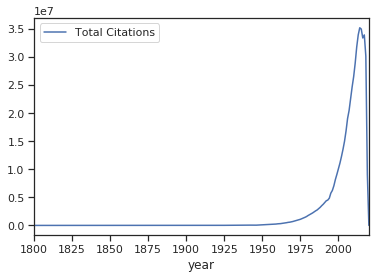

In [43]:
citations_year.to_dataframe().sort_values("year").plot(x="year", y="Total Citations")

In [44]:
disease_citations = disease_citations.join(citations_year, on="year")

NameError: name 'disease_citations' is not defined

In [103]:
disease_citations["Citations Norm"] = disease_citations["Citations"]/disease_citations["Total Citations"]

In [104]:
disease_citations = disease_citations.join(disease_names)

In [105]:
disease_citations = disease_citations.filter_by(spothlight,"disease")

In [45]:
def norm_disease_citations(disease_citations, citations_year):
    disease_citations = disease_citations.join(citations_year, on="year")
    disease_citations["Citations Norm"] = disease_citations["Citations"]/disease_citations["Total Citations"]
    return disease_citations.join(disease_names)

In [46]:
disease_citations_med = norm_disease_citations(disease_citations_med, citations_year_med)
disease_citations_viro = norm_disease_citations(disease_citations_viro, citations_year_viro)

In [47]:
disease_citations_med  = disease_citations_med.filter_by(spothlight,"disease")
disease_citations_viro  = disease_citations_viro.filter_by(spothlight,"disease")

In [48]:
disease_citations.save("output/Papers/citations_sars.csv")

NameError: name 'disease_citations' is not defined

In [107]:
citations_race = convert_to_barchart_format(disease_citations,"disease",year_column="year",count_column="Citations" )

100%|██████████| 9/9 [00:00<00:00, 318.88it/s]


In [104]:
citations_race.to_csv("output/Papers/citations_race3.csv", index=False)

In [108]:
disease_citations.groupby(["disease"], {"Citations": agg.SUM("Citations")}).sort("Citations",False)

disease,Citations
HIV/AIDS,5216473
Influenza,1551404
Hepatitis C,1480696
Hepatitis B,1059295
Swine Flu,197769
Avian Influenza,144337
SARS,143508
Ebola,114797
MERS Coronavirus,20230


### Publications Corrolation GDB

Normlize paper number:

In [24]:
def nomalize_disease_publications(diseases_mag, mag):
    diseases_pub_count = diseases_mag.groupby(["disease","Year"], {"Number of papers": agg.COUNT()})
    papers_year = mag.groupby("Year", {"Total Number of papers": agg.COUNT()})
    diseases_pub_count = diseases_pub_count.join(papers_year,{"Year":"Year"})
    diseases_pub_count["NPR"] = diseases_pub_count["Number of papers"] / diseases_pub_count["Total Number of papers"]
    diseases_pub_count = diseases_pub_count.rename({"disease":"Disease"})
    return diseases_pub_count.sort(["Disease","Year"])
    

In [148]:
diseases_pub_count = diseases_mag.groupby(["disease","Year"], {"Number of papers": agg.COUNT()})


In [149]:
papers_year = med_mag.groupby("Year", {"Total Number of papers": agg.COUNT()})

In [150]:
diseases_pub_count = diseases_pub_count.join(papers_year,{"Year":"Year"})


In [151]:
diseases_pub_count["NPR"] = diseases_pub_count["Number of papers"] / diseases_pub_count["Total Number of papers"]

In [113]:
# pubmed_gdb = pubmed_gdb.merge(papers_year,left_on="year", right_index=True)

Pubmed

### Publications - Citation

#### NPR

In [25]:
diseases_pub_count_viro = nomalize_disease_publications(diseases_viro_mag, viro_mag)
diseases_pub_count_med = nomalize_disease_publications(diseases_mag, med_mag)

In [26]:
diseases_pub_count_viro["Type"] = "Virolgy"
diseases_pub_count_med["Type"] = "Medicine"
diseases_pub_count = diseases_pub_count_viro.append(diseases_pub_count_med)


In [27]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr):
    for data in sf_corr.groupby("Disease"):
        if len(data[1]) >5:
            yield data[1].sort_values("Year")

In [28]:
diseases_pub_count = diseases_pub_count.filter_by(spothlight,"Disease")
# diseases_pub_count = diseases_pub_count[diseases_pub_count["Year"]>2001]

In [29]:
pub = SFrame()
for d,y in zip(spothlight, years):
    pub = pub.append( diseases_pub_count[(diseases_pub_count["Disease"]==d)&(diseases_pub_count["Year"]>=y)])

In [30]:
pub["Normalized Paper Rate"] = pub["NPR"]

In [122]:
pub[(pub["Year"]>=1980)&(pub["Type"]== "Medicine")&(pub["Disease"]== "MERS Coronavirus")]["NPR"].max()

0.00015181674032589993

In [123]:
pub[(pub["Year"]>=1980)&(pub["Type"]== "Medicine")&(pub["Disease"]== "SARS")]["NPR"].max()

0.002524398401822807

In [124]:
0.002524398401822807/0.00015181674032589993


16.627931784095516

IndexError: list index out of range

<Figure size 576x432 with 0 Axes>

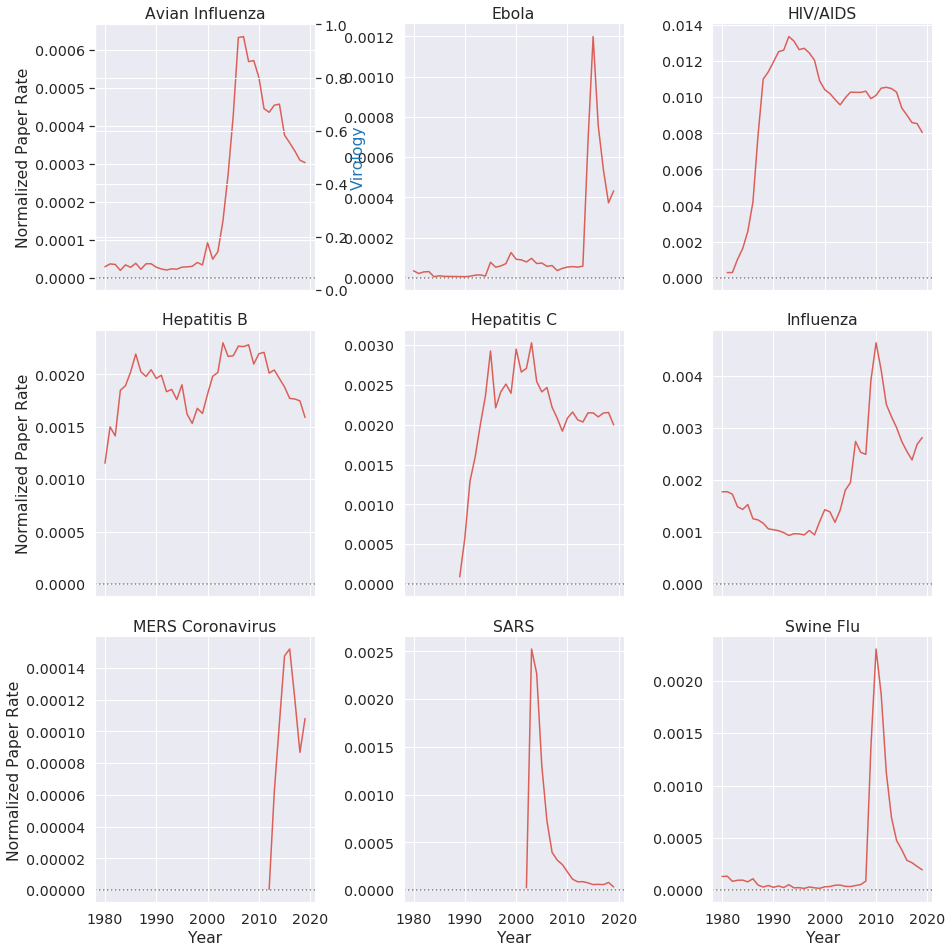

In [116]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NPR6.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(pub[(pub["Year"]>=1980)&(pub["Type"]== "Medicine")].to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        grid = create_gird(pd.concat(curr_f),"Disease","Type","Year", "Normalized Paper Rate",False,False)
        for ax in grid.axes:
            ax2 = ax.twinx()
            color = 'tab:blue'
            ax2.set_ylabel('Virology', color=color)  # we already handled the x-label with ax1
            d = ax.get_title().split(" = ")[1]
            df = pub[(pub["Year"]>=1980)&(pub["Type"]== "Virolgy")&(pub["Disease"]== d)].to_dataframe()
            ax2.plot(df["Year"], df["NPR"], color=color)
            ax2.tick_params(axis='y', labelcolor=color)
#         plt.title('')
        plt.tight_layout()

        pdf.savefig()
        plt.close()
#         plt.clf()



In [117]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/Virolgy_NPR.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(pub[(pub["Year"]>=1980)&(pub["Type"]== "Virolgy")].to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Type","Year", "Normalized Paper Rate",False,False)
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

In [118]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/Medicine_NPR.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(pub[(pub["Year"]>=1980)&(pub["Type"]== "Medicine")].to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Type","Year", "Normalized Paper Rate",False,False)
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

array([<matplotlib.axes._subplots.AxesSubplot object at 0x7f76bd58e470>,
      dtype=object)

In [56]:
pub["Normalized Paper Rate"] = np.log(pub["NPR"])

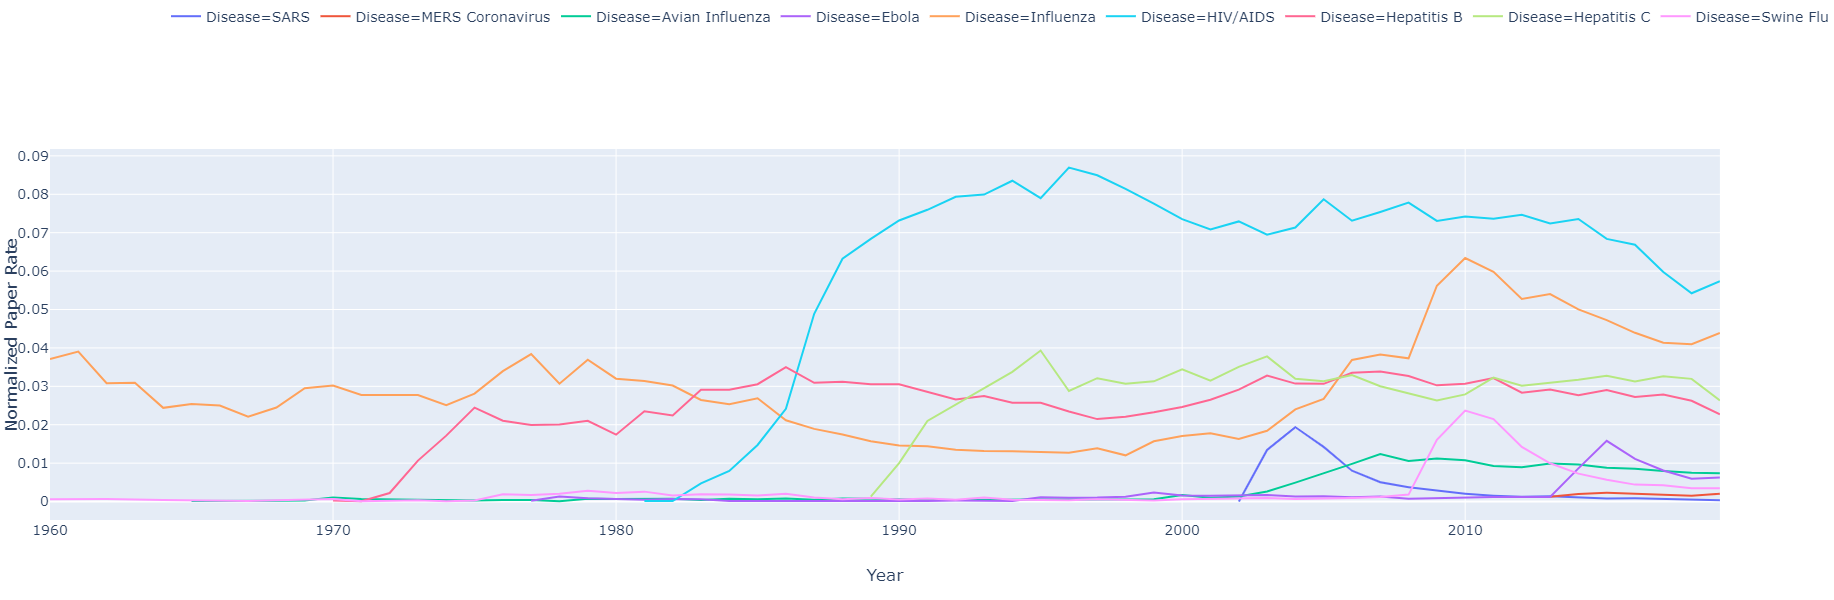

In [49]:
import plotly.express as px

fig = px.line(pub[(pub["Type"]=="Virolgy")&(pub["Year"]>1959)].to_dataframe(), x="Year", y="Normalized Paper Rate",color="Disease")
fig.update_layout({"legend":{"x":.1,"y":1.4}, "margin":{"t":0,"l":0},"legend_orientation":"h"},  font=dict(
        size=14,
    ))
fig.show()

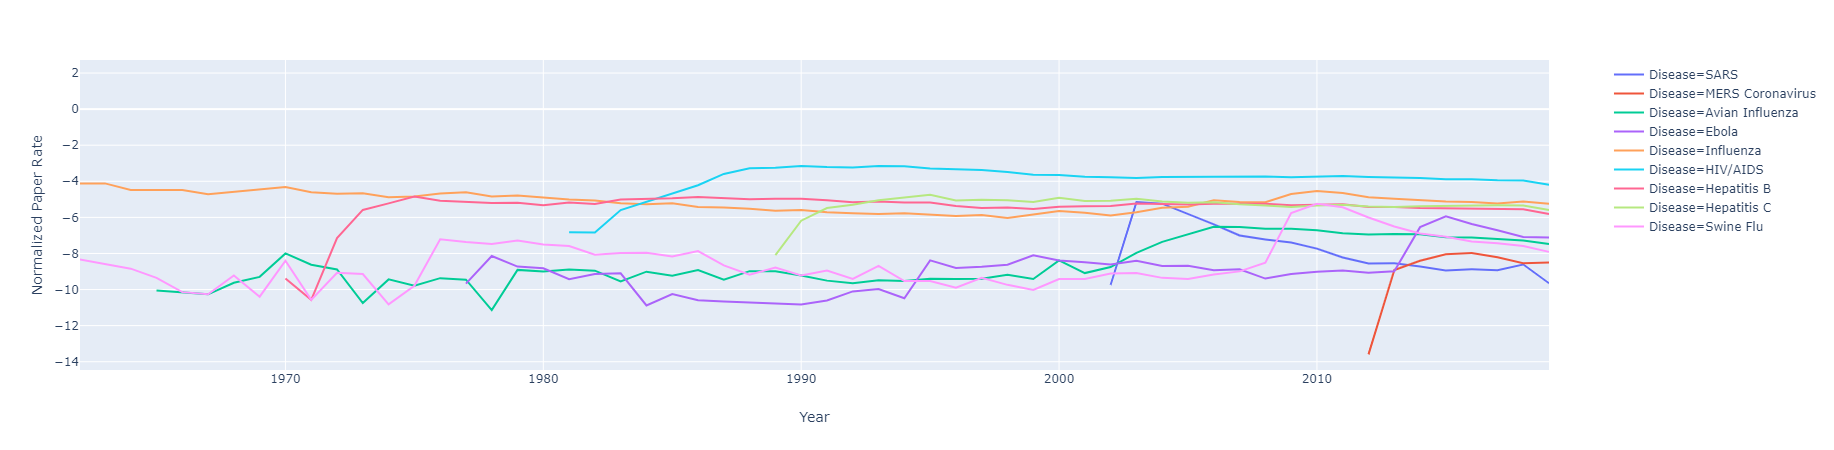

In [161]:
import plotly.express as px

fig = px.line(pub[pub["Type"]=="Virolgy]".to_dataframe(), x="Year", y="Normalized Paper Rate",color="Disease")
fig.show()

In [64]:
diseases_pub_count_df = diseases_pub_count.to_dataframe().sort_values(["Disease", "Year"])

In [65]:
diseases_pub_count_smooth= diseases_pub_count_df[["Disease","Number of papers","Total Number of papers"]].groupby("Disease").rolling(5).mean()

In [66]:
diseases_pub_count_smooth = diseases_pub_count_smooth.reset_index()

In [67]:
diseases_pub_count_smooth["Year"] = diseases_pub_count_df["Year"].values

In [68]:
diseases_pub_count_smooth["NPR"] = diseases_pub_count_smooth["Number of papers"]/diseases_pub_count_smooth["Total Number of papers"]

In [69]:
diseases_pub_count_smooth = diseases_pub_count_smooth.sort_values(["Disease", "Year"])

In [70]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NPR_smooth.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(diseases_pub_count_smooth))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NPR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



100%|██████████| 1/1 [00:01<00:00,  1.85s/it]


<Figure size 576x432 with 0 Axes>

#### NCR

In [129]:
diseases_mag.head(1)

Columns:
	PaperId	int
	Rank	int
	Doi	str
	DocType	str
	PaperTitle	str
	OriginalTitle	str
	BookTitle	str
	Year	int
	Date	str
	Publisher	str
	JournalId	int
	ConferenceSeriesId	int
	ConferenceInstanceId	int
	Volume	int
	Issue	int
	FirstPage	int
	LastPage	int
	ReferenceCount	int
	CitationCount	int
	EstimatedCitation	int
	OriginalVenue	str
	CreatedDate	str
	Ref Number	int
	Total Citations by Year	dict
	Total Citations by Year without Self Citations	dict
	Authors List Sorted	array
	Authors Number	int
	Urls	list
	Dict of Year_Citation Number	dict
	id	int
	disease	str

Rows: 1

Data:
+------------+-------+-----+---------+-------------------------------+
|  PaperId   |  Rank | Doi | DocType |           PaperTitle          |
+------------+-------+-----+---------+-------------------------------+
| 2374592191 | 23213 |     | Journal | visual analysis of feature... |
+------------+-------+-----+---------+-------------------------------+
+-------------------------------+-----------+------+------------+-----------+
|         OriginalTitle         | BookTitle | Year |    Date    | Publisher |
+-------------------------------+-----------+------+------------+-----------+
| Visual analysis of feature... |           | 2014 | 2014-01-01 |           |
+-------------------------------+-----------+------+------------+-----------+
+------------+--------------------+----------------------+--------+-------+-----------+
| JournalId  | ConferenceSeriesId | ConferenceInstanceId | Volume | Issue | FirstPage |
+------------+--------------------+----------------------+--------+-------+-----------+
| 2764895004 |        None        |         None         |  None  |  None |    None   |
+------------+--------------------+----------------------+--------+-------+-----------+
+----------+----------------+---------------+-------------------+-----+
| LastPage | ReferenceCount | CitationCount | EstimatedCitation | ... |
+----------+----------------+---------------+-------------------+-----+
|   None   |       0        |       0       |         0         | ... |
+----------+----------------+---------------+-------------------+-----+
[1 rows x 31 columns]

In [134]:
!mv /storage/homedir/dima/.scidyn2/MAG/sframes/PaperFieldsOfStudy.SFrame /storage/homedir/dima/.scidyn2/MAG/sframes/PaperFieldsOfStudy.sframe

In [61]:
def clean_disease_citations(disease_citations):
    disease_citations = disease_citations.rename({"year":"Year","Citations Norm":"NCR", "disease": "Disease"})
    disease_citations = disease_citations.join(disease_names, {"id":"id"})
    disease_citations = disease_citations.sort(["Disease", "Year"]) 
    disease_citations = disease_citations.to_dataframe()
    disease_citations = disease_citations[disease_citations["Year"].notna()]
    disease_citations = disease_citations[disease_citations["Year"]<2019]
    return disease_citations.reset_index()

In [120]:
disease_citations = disease_citations.rename({"year":"Year","Citations Norm":"NCR", "disease": "Disease"})
disease_citations = disease_citations.join(disease_names, {"id":"id"})
disease_citations = disease_citations.sort(["Disease", "Year"])

In [121]:
disease_citations = disease_citations.to_dataframe()

In [122]:
disease_citations = disease_citations[disease_citations["Year"].notna()]

In [123]:
disease_citations = disease_citations[disease_citations["Year"]<2019]

In [124]:
disease_citations = disease_citations.reset_index()

In [125]:
disease_citations = disease_citations[disease_citations["Disease"].isin(spothlight)]
# disease_citations = disease_citations[disease_citations["Year"]>2001]

In [62]:
disease_citations_med = clean_disease_citations(disease_citations_med)
disease_citations_viro = clean_disease_citations(disease_citations_viro)

In [63]:
disease_citations_med["Type"] = "Medicine"
disease_citations_viro["Type"] = "Virology"

disease_citations = disease_citations_med.append(disease_citations_viro)


In [64]:
cite = pd.DataFrame()
for d,y in zip(spothlight, years):
    cite = cite.append( disease_citations[(disease_citations["Disease"]==d)&(disease_citations["Year"]>=y)])

In [106]:
cite["Normalized Citaion Rate"] = cite["NCR"]

In [109]:
list(get_d(cite[(cite["Year"]>=1980)&(cite["Type"]== "Medicine")])

SyntaxError: unexpected EOF while parsing (<ipython-input-109-9607e1a539da>, line 1)

In [112]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
sns.set(font_scale=1.3)
sns.set(style="ticks")

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/Medicine_NCR.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(cite[(cite["Year"]>=1980)&(cite["Type"]== "Medicine")]))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Type","Year", "Normalized Citaion Rate", False, legend=False)
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

In [113]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
sns.set(font_scale=1.3)
# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/Virology_NCR.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(cite[(cite["Year"]>=1980)&(cite["Type"]== "Virology")]))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Type","Year", "Normalized Citaion Rate", False, legend=False)
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

In [146]:
cite["Normalized Citation Rate"] = np.log(cite["NCR"])

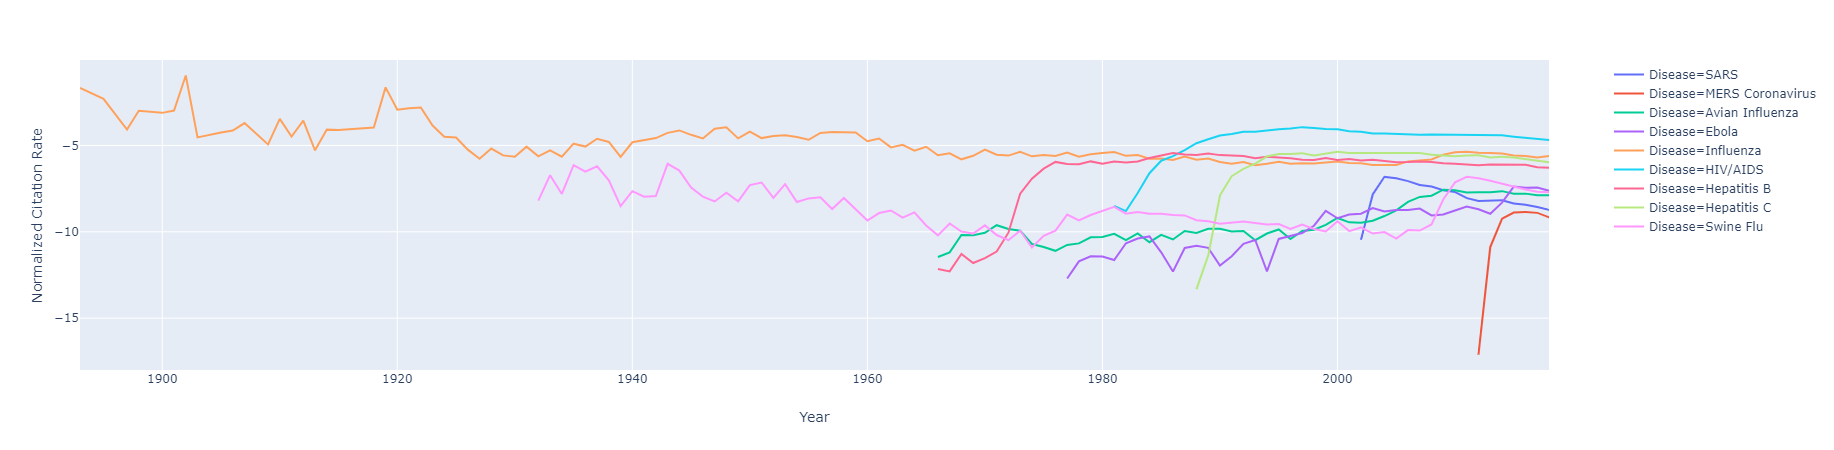

In [147]:
import plotly.express as px

fig = px.line(cite, x="Year", y="Normalized Citation Rate",color="Disease")
fig.show()

In [80]:
diseases_pub_count[diseases_pub_count["Disease"]=="HIV/AIDS"]

Year,Disease,Number of papers,Total Number of papers,NPR
2002,HIV/AIDS,3939,861251,0.00457357959526317
2003,HIV/AIDS,4002,931311,0.004297168185493353
2004,HIV/AIDS,4559,1026689,0.00444048782055715
2005,HIV/AIDS,5176,1103601,0.004690100860727745
2006,HIV/AIDS,5720,1228906,0.0046545464014334705
2007,HIV/AIDS,6512,1294751,0.005029538498135935
2008,HIV/AIDS,7046,1414934,0.004979737570798355
2009,HIV/AIDS,7386,1555030,0.00474974759329402
2010,HIV/AIDS,8080,1596381,0.005061448363517231
2011,HIV/AIDS,8881,1702870,0.005215312971630247


In [79]:
disease_citations[disease_citations["Disease"]=="HIV/AIDS"]

,index,Year,Disease,Citations,Total Citations,NCR,id,disease
79,81,2002,HIV/AIDS,4277,12286139,0.000348,91,HIV/AIDS
80,82,2003,HIV/AIDS,14911,13562845,0.001099,91,HIV/AIDS
81,83,2004,HIV/AIDS,31529,14999106,0.002102,91,HIV/AIDS
82,84,2005,HIV/AIDS,50976,16833801,0.003028,91,HIV/AIDS
83,85,2006,HIV/AIDS,71237,19047093,0.003740,91,HIV/AIDS
84,86,2007,HIV/AIDS,94479,20484542,0.004612,91,HIV/AIDS
85,87,2008,HIV/AIDS,118533,22553047,0.005256,91,HIV/AIDS
86,88,2009,HIV/AIDS,143661,24677252,0.005822,91,HIV/AIDS
87,89,2010,HIV/AIDS,168510,26508572,0.006357,91,HIV/AIDS
88,90,2011,HIV/AIDS,200911,28896080,0.006953,91,HIV/AIDS


In [73]:
disease_citations_smooth= disease_citations[["Disease","Citations","Total Citations"]].groupby("Disease").rolling(3, min_periods=2).mean()

In [74]:
disease_citations_smooth = disease_citations_smooth.reset_index()

In [75]:
disease_citations_smooth["Year"] = disease_citations["Year"]

In [76]:
disease_citations_smooth["NCR"] = disease_citations_smooth["Citations"]/disease_citations_smooth["Total Citations"]

In [77]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NCR_smooth2.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(disease_citations_smooth))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NCR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

## Semantic Scholar

In [333]:
diseases_sm = load_sframe("Data/sm/diseases_sm.sframe")

### Citations to time

In [336]:
disease_citations = diseases_sm.stack("inCitations",new_column_name=["cite paper id", "cite year"], drop_na=True)

In [337]:
disease_citations = disease_citations.groupby(["disease","cite year"], {"Citations": agg.COUNT("cite paper id")})

In [338]:
disease_citations["cite year"] = disease_citations["cite year"].astype(int)

In [339]:
disease_citations = disease_citations.rename({"cite year": "year"})

In [343]:
disease_citations.sort("Citations", False)

year,disease,Citations
2017,HIV/AIDS,185802
2016,HIV/AIDS,163420
2015,HIV/AIDS,161191
2018,HIV/AIDS,160822
2014,HIV/AIDS,152319
2013,HIV/AIDS,136507
2012,HIV/AIDS,117181
2019,HIV/AIDS,99786
2011,HIV/AIDS,94165
2010,HIV/AIDS,71615


In [199]:
citations_year = disease_citations.groupby(["year"], operations={"Total Citations": agg.SUM("Citations")})

In [200]:
citations_year["year"] = citations_year["year"].astype(int)

In [201]:
disease_citations

year,disease,Citations
2007,Venezuelan equineencephalitis ...,131
2012,Parainfluenza virus,313
2018,Angiostrongyliasis,73
1995,Gastroenteritis,42
1998,Diphtheria,76
1949,Escherichia coli diarrhea,1
2013,Brazilian purpuric fever,1
1957,Diphtheria,1
2003,Fungal infection,84
1984,Malaria,37


In [175]:
citations_year.sort("Total Citations",False)

year,Total Citations
2017,902792
2016,802772
2018,801145
2015,765356
2014,698638
2013,621743
2012,543889
2019,502158
2011,448514
2010,359791


In [176]:
import turicreate as tc
tc.visualization.scatter(citations_year["year"], citations_year["Total Citations"])

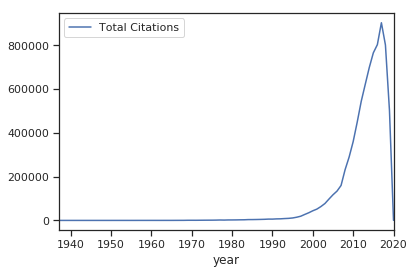

In [177]:
citations_year.to_dataframe().sort_values("year").plot(x="year", y="Total Citations")

In [202]:
disease_citations = disease_citations.join(citations_year)

In [203]:
disease_citations["Citations Norm"] = disease_citations["Citations"]/disease_citations["Total Citations"]

In [204]:
disease_citations

year,disease,Citations,Total Citations,Citations Norm
2007,Venezuelan equineencephalitis ...,131,159660,0.0008204935487911813
2012,Parainfluenza virus,313,543889,0.0005754850714024368
2018,Angiostrongyliasis,73,801145,9.111958509383445e-05
1995,Gastroenteritis,42,11205,0.003748326639892905
1998,Diphtheria,76,27320,0.0027818448023426063
1949,Escherichia coli diarrhea,1,14,0.07142857142857142
2013,Brazilian purpuric fever,1,621743,1.6083815981844589e-06
1957,Diphtheria,1,79,0.012658227848101266
2003,Fungal infection,84,77162,0.001088618750161997
1984,Malaria,37,3775,0.00980132450331126


In [205]:
disease_citations = disease_citations.join(disease_names)

In [206]:
disease_citations = disease_citations.filter_by(spothlight,"disease")
disease_citations = disease_citations[disease_citations["year"]>2001]

In [207]:
disease_citations.save("output/Papers/citations_sars.csv")

In [39]:
citations_race = convert_to_barchart_format(disease_citations,"disease",year_column="year",count_column="Citations" )

100%|██████████| 2/2 [00:00<00:00, 265.50it/s]


In [104]:
citations_race.to_csv("output/Papers/citations_race3.csv", index=False)

In [186]:
disease_citations.groupby(["disease"], {"Citations": agg.SUM("Citations")}).sort("Citations",False)

disease,Citations
avian influenza,61307
Ebola,54153
SARS,41024
MERS Coronavirus,13027


,index,Year,Disease,Citations,Total Citations,NCR,id,disease
17,19,2011,MERS Coronavirus,5,448514,0.000011,316,MERS Coronavirus
18,20,2012,MERS Coronavirus,2,543889,0.000004,316,MERS Coronavirus
19,21,2013,MERS Coronavirus,347,621743,0.000558,316,MERS Coronavirus
20,22,2014,MERS Coronavirus,1663,698638,0.002380,316,MERS Coronavirus
21,23,2015,MERS Coronavirus,2212,765356,0.002890,316,MERS Coronavirus
22,24,2016,MERS Coronavirus,2703,802772,0.003367,316,MERS Coronavirus
23,25,2017,MERS Coronavirus,2558,902792,0.002833,316,MERS Coronavirus
24,26,2018,MERS Coronavirus,1742,801145,0.002174,316,MERS Coronavirus
25,28,2002,SARS,61,63234,0.000965,203,SARS
26,29,2003,SARS,1033,77162,0.013387,203,SARS


### Publications Corrolation GDB

Normlize paper number:

In [78]:
diseases_sm

paper id,sources,title,venue,year
c491f893ebdd0b423e9a5f4689382f535670dfff ...,[Medline],Longitudinal genomicsurveillance of ...,Genome Biology,2017
fc262595d39cc0c52dab974b062f51fd5f2c8ef3 ...,[Medline],Recurrence Prevention inPatients with Urinary ...,TheScientificWorldJournal,2004
0f1951b30eaf1bca60d50f0b44b291589c98ced5 ...,[],HIV/AIDS: The ZimbabweanSituation and Trends ...,,2013
0f1951b30eaf1bca60d50f0b44b291589c98ced5 ...,[],HIV/AIDS: The ZimbabweanSituation and Trends ...,,2013
3ce84555a29993bdd3d2cf84a8e67ebeeb835eae ...,[Medline],Cost-EffectivenessAnalysis of Prophylactic ...,PharmacoEconomics,2011
2f7b33f603e80fb82edd631338340dd14dadbab8 ...,[Medline],"Human papillomavirusprevalence, viral load ...",The Brazilian journal ofinfectious diseases : an ...,2002
e5feb386f02782767e8af9c986e3a777174ab57f ...,[],Einführung 2Inhaltsverzeichnis 3 ...,,2014
bd592779a2227846ee3b81a0b846955b4d909498 ...,[Medline],Factors Associated withImmunological Discord ...,Japanese journal ofinfectious diseases ...,2015
00e1f9a87e4043c7ce6626155b572b68efebf5dd ...,[],Seroprevalence of HIV inANC clinic attendees and ...,,2017
b246cc0c3fe8fdff761383afcf8da052d5db88a9 ...,[Medline],The effects of earlysyphilis on CD4 counts ...,Sexually transmittedinfections ...,2005


In [120]:
diseases_pub_count = diseases_sm.groupby(["disease","year"], {"Number of papers": agg.COUNT()})


In [121]:
papers_year = diseases_sm.groupby("year", {"Total Number of papers": agg.COUNT()})

In [122]:
diseases_pub_count = diseases_pub_count.join(papers_year,{"year":"year"})


In [123]:
diseases_pub_count["NPR"] = diseases_pub_count["Number of papers"] / diseases_pub_count["Total Number of papers"]

In [83]:
# pubmed_gdb = pubmed_gdb.merge(papers_year,left_on="year", right_index=True)

### Publications - Citation

#### NPR

In [124]:
diseases_pub_count = diseases_pub_count.rename({"year":"Year", "disease":"Disease"})

In [125]:
diseases_pub_count = diseases_pub_count.sort(["Disease","Year"])

In [126]:
pubmed_gdb_citation_log["NPR"] = np.log(pubmed_gdb_citation3["NPR"] )
pubmed_gdb_citation_log["NCR"] = np.log(pubmed_gdb_citation3["NCR"] )

NameError: name 'pubmed_gdb_citation3' is not defined

In [86]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr):
    for data in sf_corr.groupby("Disease"):
        if len(data[1]) >5:
            yield data[1].sort_values("Year")

In [163]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from  matplotlib.ticker import FuncFormatter

sns.set(style="ticks")
def create_gird(df, col, hue,x,y, sharey=False):

    # Initialize a grid of plots with an Axes for each walk
    grid = sns.FacetGrid(df, col=col, hue=hue, palette="tab20c",
                         col_wrap=2, height=4.5,sharey=sharey)
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x)))

    # Draw a horizontal line to show the starting point
    grid.map(plt.axhline, y=0, ls=":", c=".5")

    # Draw a line plot to show the trajectory of each random walk
    grid.map(plt.plot, x, y)

    # Adjust the tick positions and labels
    # grid.set(xticks=np.arange(5), yticks=[-3, 3],
    #          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

    # Adjust the arrangement of the plots
    grid.fig.tight_layout(w_pad=1)
    return grid

In [152]:
diseases_pub_count[diseases_pub_count["Disease"]=="avian influenza"]

Disease,Year,Number of papers,Total Number of papers,NPR
avian influenza,None,16,3605,0.004438280166435506
avian influenza,1969,1,440,0.0022727272727272726
avian influenza,1970,1,531,0.0018832391713747645
avian influenza,1971,2,547,0.003656307129798903
avian influenza,1976,1,829,0.0012062726176115801
avian influenza,1979,1,1021,0.0009794319294809011
avian influenza,1980,2,1034,0.0019342359767891683
avian influenza,1982,5,1220,0.004098360655737705
avian influenza,1983,2,1363,0.001467351430667645
avian influenza,1984,1,1462,0.0006839945280437756


In [154]:
diseases_pub_count = diseases_pub_count.filter_by(spotlight,"Disease")
diseases_pub_count = diseases_pub_count[diseases_pub_count["Year"]>2001]

In [164]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NPR2.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(diseases_pub_count.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NPR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



100%|██████████| 1/1 [00:00<00:00,  1.11it/s]


<Figure size 576x432 with 0 Axes>

In [156]:
diseases_pub_count_df = diseases_pub_count.to_dataframe().sort_values(["Disease", "Year"])

In [157]:
diseases_pub_count_smooth= diseases_pub_count_df[["Disease","Number of papers","Total Number of papers"]].groupby("Disease").rolling(5).mean()

In [158]:
diseases_pub_count_smooth = diseases_pub_count_smooth.reset_index()

In [159]:
diseases_pub_count_smooth["Year"] = diseases_pub_count_df["Year"].values

In [160]:
diseases_pub_count_smooth["NPR"] = diseases_pub_count_smooth["Number of papers"]/diseases_pub_count_smooth["Total Number of papers"]

In [161]:
diseases_pub_count_smooth = diseases_pub_count_smooth.sort_values(["Disease", "Year"])

In [95]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NPR_smooth.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(diseases_pub_count_smooth))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NPR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



NameError: name 'diseases_pub_count_smooth' is not defined

<Figure size 576x432 with 0 Axes>

#### NCR

In [209]:
disease_citations = disease_citations.rename({"year":"Year","Citations Norm":"NCR", "disease": "Disease"})
disease_citations = disease_citations.join(disease_names, {"id":"id"})
disease_citations = disease_citations.sort(["Disease", "Year"])

In [210]:
disease_citations = disease_citations.to_dataframe()

In [211]:
disease_citations = disease_citations[disease_citations["Year"].notna()]

In [212]:
disease_citations = disease_citations[disease_citations["Year"]<2019]

In [213]:
disease_citations = disease_citations.reset_index()

In [214]:
disease_citations = disease_citations[disease_citations["Disease"].isin(spothlight)]
disease_citations = disease_citations[disease_citations["Year"]>2001]

In [215]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NCR2.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(disease_citations))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NCR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



100%|██████████| 1/1 [00:01<00:00,  1.16s/it]


<Figure size 576x432 with 0 Axes>

In [226]:
disease_citations_smooth= disease_citations[["Disease","Citations","Total Citations"]].groupby("Disease").rolling(3, min_periods=2).mean()

In [227]:
disease_citations_smooth = disease_citations_smooth.reset_index()

In [228]:
disease_citations_smooth["Year"] = disease_citations["Year"]

In [229]:
disease_citations_smooth["NCR"] = disease_citations_smooth["Citations"]/disease_citations_smooth["Total Citations"]

In [230]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NCR_smooth2.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(disease_citations_smooth))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NCR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



100%|██████████| 1/1 [00:00<00:00,  1.24it/s]


<Figure size 576x432 with 0 Axes>

## Pubmed

In [254]:
diseases_pubmed = load_sframe("Data/pubmed/diseases_pubmed.sframe")

In [99]:
hiv = diseases_pubmed[diseases_pubmed["disease"]=="HIV/AIDS"]

In [107]:
hiv = hiv.stack("mesh_terms", new_column_name="mesh_terms")

In [109]:
hiv["mesh_terms"].value_counts()

value,count
D006801:Humans,196310
D015658:HIV Infections,116658
D008297:Male,89902
D005260:Female,83043
D015497:HIV-1,51519
D000163:AcquiredImmunodeficiency Synd ...,44245
D008875:Middle Aged,44084
D000328:Adult,42823
D000328:Adult,33800
,19044


In [111]:
hiv2 = diseases_pubmed_mesh[diseases_pubmed_mesh["disease"]=="HIV/AIDS"]

In [112]:
hiv2 = hiv2.stack("mesh_terms", new_column_name="mesh_terms")

In [113]:
hiv2["mesh_terms"].value_counts()

value,count
D006678:HIV,17454
D006801:Humans,15904
D015658:HIV Infections,8312
D008297:Male,4674
D005260:Female,4313
D000163:AcquiredImmunodeficiency Synd ...,3177
D008875:Middle Aged,2214
D000328:Adult,1916
D014779:VirusReplication ...,1897
D000328:Adult,1752


### Publications Corrolation Promed

In [7]:
def join_pubmed_promed(diseases_mag, diseases_id, diseases_occurrences):
    diseases_pub_count = diseases_mag.groupby(["disease","year"], {"Number of papers": agg.COUNT()})
    sf_corr = diseases_pub_count.join(diseases_id)
    sf_corr = sf_corr.groupby(["id","year"], {"Number of papers":agg.SUM("Number of papers")})
    return sf_corr.join(diseases_occurrences, on={"id":"id","year":"year"}).to_dataframe()

In [8]:
pubmed_corr = join_pubmed_promed(diseases_pubmed, diseases_id, diseases_occurrences)

NameError: name 'diseases_occurrences' is not defined

### Publications Corrolation GBD

In [84]:
gdb = SFrame.read_csv("Data/gdb/gdb.csv")
# gdb["cause"] = gdb["cause"].apply(lambda x: x.lower())

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/gdb/gdb.csv

Parsing completed. Parsed 100 lines in 0.240041 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[str,str,str,str,str,str,int,float,float,float]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/gdb/gdb.csv

Parsing completed. Parsed 22176 lines in 0.057894 secs.

In [85]:
gdb = gdb[(gdb["metric"]=="Rate")&(gdb["sex"]=="Both")]

In [10]:
diseases_pubmed = diseases_pubmed.join(diseases_id, on={"disease":"diseases"})

In [72]:
len(gdb["cause"].unique())

50

In [74]:
gdb_diseases

id,disease,GDB
100,Ascariasis,Ascariasis
72,Bacillus cereus foodpoisoning ...,Diarrheal diseases
12,Borna virus encephalitis,Encephalitis
23,Brainerd diarrhea,Diarrheal diseases
243,California encephalitis,Encephalitis
42,Campylobacteriosis,Diarrheal diseases
200,Chlamydia,Chlamydial infection
331,Cysticercosis,Cysticercosis
78,Dengue,Dengue
298,Diphtheria,Diphtheria


In [75]:
len(gdb)

22176

In [79]:
diseases_id

diseases,id
reye's syndrome,152
brain abscess,254
murray valley and kunjin,323
wesselsbron,311
spotted fevers,102
entomophthoromycosis,178
hendra virus,300
porocephaliasis,151
chromomycosis,89
bejel,294


In [11]:
gbd = gbd.join(diseases_id, on={"cause":"diseases"})

In [12]:
def join_gdb(academic_sf, diseases_occurrences):
    diseases_pub_count = academic_sf.groupby(["id","year"], {"Number of papers": agg.COUNT()})
#     sf_corr = diseases_pub_count.join(diseases_id)
#     sf_corr = sf_corr.groupby(["id","year"], {"Number of papers":agg.SUM("Number of papers")})
    return diseases_pub_count.join(diseases_occurrences, on={"id":"id","year":"year"}).to_dataframe()

In [13]:
pubmed_gdb = join_gdb(diseases_pubmed, gbd)

In [14]:
dalys = pubmed_gdb[pubmed_gdb["measure"] =="DALYs (Disability-Adjusted Life Years)"]
deaths = pubmed_gdb[pubmed_gdb["measure"] =="Deaths"]

In [15]:
pubmed_gdb = dalys.merge(deaths,how="left",left_on=["id","year", "metric"],right_on=["id","year", "metric"], suffixes=("","_Deaths"))

In [16]:
pubmed_gdb = pubmed_gdb[["id", "year", "Number of papers","cause","metric",  'val','val_Deaths']]

In [17]:
pubmed_gdb = pubmed_gdb[pubmed_gdb["metric"] =="Rate"]

Normlize paper number:

In [ ]:
diseases_pub_count = diseases_pubmed.groupby(["id","year"], {"Number of papers": agg.COUNT()})
diseases_pub_count = diseases_pub_count.join(SFrame(disease_names), {"id":"id"})

In [20]:
papers_year = diseases_pub_count.to_dataframe().groupby("year").sum()["Number of papers"]

In [21]:
diseases_pub_count = diseases_pub_count.to_dataframe().merge(papers_year,left_on="year", right_index=True)
diseases_pub_count["Normalized Number of papers"] = diseases_pub_count["Number of papers_x"] / diseases_pub_count["Number of papers_y"]

In [155]:
# pubmed_gdb = pubmed_gdb.merge(papers_year,left_on="year", right_index=True)

In [22]:
pubmed_gdb = pubmed_gdb.merge(papers_year,left_on="year", right_index=True)

In [23]:
pubmed_gdb["Normalized Number of papers"] = pubmed_gdb["Number of papers_x"] / pubmed_gdb["Number of papers_y"]

Join with Promed

In [41]:
pubmed_gdb[pubmed_gdb["cause"]=="ascariasis"].sort_values("year").corr()

,id,year,Number of papers_x,val,val_Deaths,Number of papers_y,Normalized Number of papers
id,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,NaN,1.000000,-0.652292,-0.994539,-0.991176,0.954993,-0.934676
Number of papers_x,NaN,-0.652292,1.000000,0.672773,0.684969,-0.545974,0.871612
val,NaN,-0.994539,0.672773,1.000000,0.997113,-0.928746,0.941281
val_Deaths,NaN,-0.991176,0.684969,0.997113,1.000000,-0.909432,0.942724
Number of papers_y,NaN,0.954993,-0.545974,-0.928746,-0.909432,1.000000,-0.865614
Normalized Number of papers,NaN,-0.934676,0.871612,0.941281,0.942724,-0.865614,1.000000


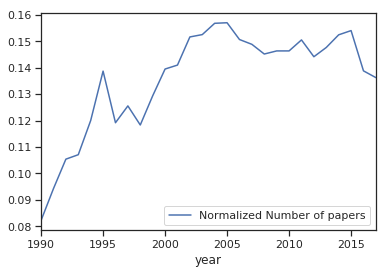

In [82]:
pubmed_gdb[pubmed_gdb["cause"]=="acute hepatitis"].sort_values("year").plot(x="year", y="Normalized Number of papers")

In [27]:
# pubmed_gdb_= pubmed_gdb_.merge(promed_diseases_agg.to_dataframe(), how="left", left_on=["id","pubdate"],  right_on=["id","year"])

## Aminer

In [121]:
diseases_miner = load_sframe("Data/aminer/diseases_aminer.sframe")
diseases_miner["year"] = diseases_miner["year"].astype(int)

### Citations to time

In [122]:
disease_citations = diseases_miner.groupby(["id","year"], {"Citations": agg.SUM("n_citation")})

In [123]:
citations_year = diseases_miner.groupby(["year"], operations={"Total Citations": agg.SUM("n_citation")})

In [124]:
disease_citations = disease_citations.join(citations_year)

In [125]:
disease_citations["Citations Norm"] = disease_citations["Citations"]/disease_citations["Total Citations"]

In [33]:
def join_aminer_promed(diseases_mag, diseases_id, diseases_occurrences):
    diseases_pub_count = diseases_mag.groupby(["disease","year"], {"Number of papers": agg.COUNT()})
    sf_corr = diseases_pub_count.join(diseases_id)
    sf_corr = sf_corr.groupby(["id","year"], {"Number of papers":agg.SUM("Number of papers")})
    return sf_corr.join(diseases_occurrences, on={"id":"id","year":"year"}).to_dataframe()

In [34]:
aminer_corr = join_aminer_promed(diseases_miner, diseases_id, diseases_occurrences)

NameError: name 'diseases_occurrences' is not defined

In [163]:
citations_race = convert_to_barchart_format(SFrame(disease_citations),"Disease",count_column="Citations" )

In [164]:
citations_race.to_csv("output/citations_race.csv", index=False)

## Semantic Scholar

In [251]:
diseases_sm = load_sframe("/data/semantic-scholar/s2-corpus-small.sframe")
diseases_sm["year"] = diseases_sm["year"].astype(int)

## Data Fusion

In [231]:
sm_papers_year = diseases_sm.groupby("year",{"Semantic": agg.COUNT()})

In [232]:
aminer_papers_year = diseases_miner.groupby("year",{"Aminer": agg.COUNT()})

NameError: name 'diseases_miner' is not defined

In [255]:
pubmed_papers_year = diseases_pubmed.groupby("year",{"PubMed":agg.COUNT()})

In [257]:
mag_papers_year =  diseases_mag.groupby("Year",{"MAG":agg.COUNT()})

In [255]:
s = diseases_sm[diseases_sm["disease"].apply(lambda x: x in{"MERS Coronavirus", "SARS"})].groupby("year",{"Semantic": agg.COUNT()})

In [282]:
s2 = diseases_sm[diseases_sm["disease"].apply(lambda x: x in{"avian influenza", "Ebola"})].groupby(["year", "disease"],{"Semantic": agg.COUNT()})

In [283]:
def turi_replace(sf, col, term):
    for k,v in term.items():
        sf[col] = sf[col].apply(lambda x: v if x==k else x)
    return sf

In [285]:
turi_replace(s2,"disease",{"avian influenza": "Avian influenza"})

disease,year,Semantic
Avian Influenza,2003,64
Avian Influenza,1976,1
Avian Influenza,None,16
Ebola,1993,1
Avian Influenza,1993,3
Ebola,1988,1
Avian Influenza,1997,4
Avian Influenza,1987,1
Ebola,2005,30
Avian Influenza,2010,373


In [275]:
s2 = s2[""]

SyntaxError: EOF while scanning triple-quoted string literal (<ipython-input-275-eb7e5d01361f>, line 1)

In [40]:
pubmed = load_sframe("Data/pubmed/pubmed.sframe")

In [41]:
pubmed_papers_year = pubmed.groupby("year",{"PubMed":agg.COUNT()})

In [52]:
mag_papers_year =  med_mag.groupby("Year",{"MAG":agg.COUNT()})

In [252]:
df = sm_papers_year.join(pubmed_papers_year,{"year":"year"}).join(mag_papers_year,{"year":"Year"}).sort("year")

NameError: name 'sm_papers_year' is not defined

In [53]:
df = pubmed_papers_year.join(mag_papers_year,{"year":"Year"}).sort("year")

In [54]:
df =df.rename({"year":"Year"})

In [55]:
df.sort("year").to_dataframe().plot(x="year")

ValueError: SFrame has no column named: 'year'

In [ ]:
df[df["Year"]<2017].sort("Year").to_dataframe().plot(x="Year")

In [56]:
df2 = df.pack_columns(column_names=["MAG","PubMed"], dtype=dict, new_column_name='Papers').stack("Papers", new_column_name=['Dataset', 'Total Papers'])

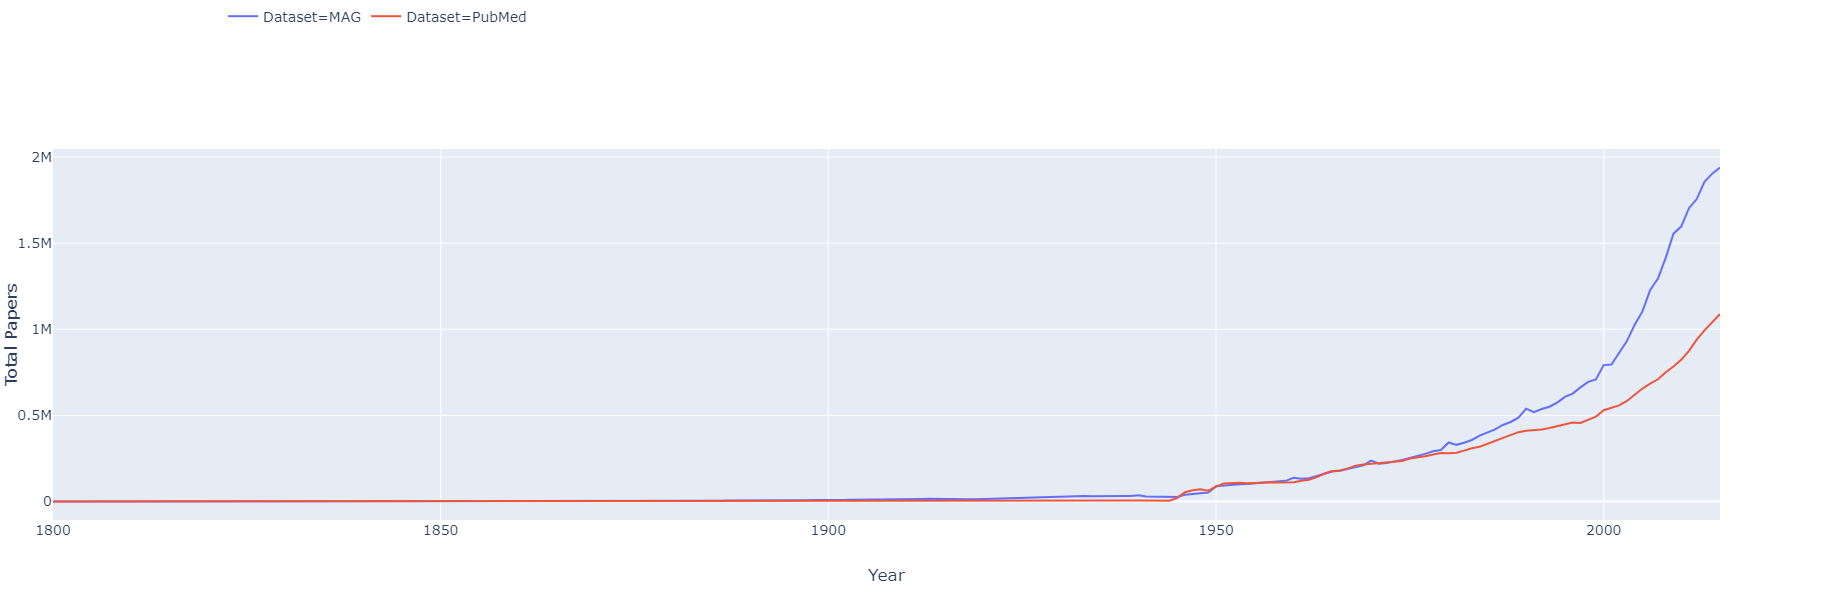

In [57]:
import plotly.express as px

fig = px.line(df2[df2["Year"]<2016].to_dataframe(), x="Year", y="Total Papers",color="Dataset")
fig.update_layout({"legend":{"x":.1,"y":1.4}, "margin":{"t":0,"l":0},"legend_orientation":"h"},  font=dict(
        size=14,
    ))

fig.show()

In [259]:
s

year,Semantic
1959,2
1996,1
1987,3
None,16
1976,1
2012,88
2015,218
2000,5
1995,4
1980,1


In [287]:
s2= s2.rename({"year":"Year","Semantic":"Total Papers", "disease": "Disease"})

In [261]:
s = s.rename({"year":"Year","Semantic":"Total Papers"})

In [288]:
s["Disease"] = "Coronavirus"

In [289]:
s = s.append(s2)

In [290]:
s = s.sort("Year")

In [291]:
s = s[s["Year"]>2001]

In [ ]:
spothlight = ["SARS","MERS Coronavirus", "Avian Influenza","Ebola", "Influenza", "HIV/AIDS","Hepatitis B","Hepatitis C", "Swine Flu"]
diseases_mag

In [308]:
mag_papers_year =  diseases_mag.filter_by(spothlight,"disease").groupby(["Year","disease"],{"Total Papers":agg.COUNT()})

In [310]:
mag_papers_year = mag_papers_year.sort("Year")

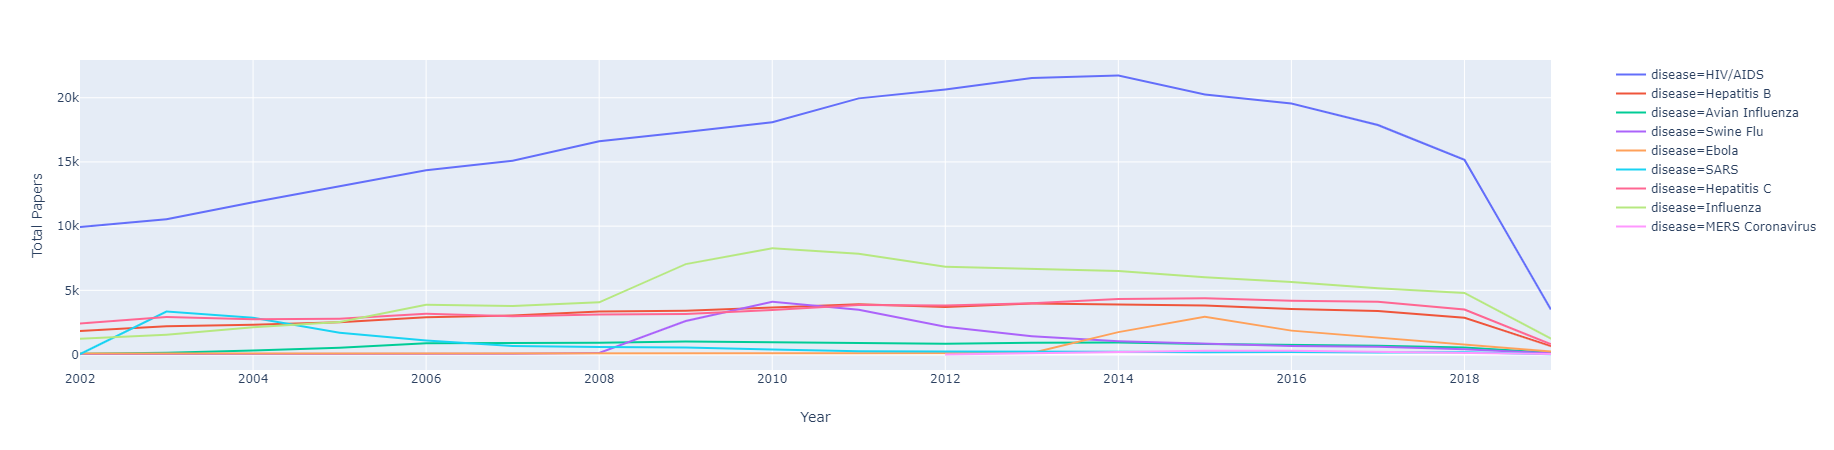

In [312]:
import plotly.express as px

fig = px.line(mag_papers_year[mag_papers_year["Year"]>2001].to_dataframe(), x="Year", y="Total Papers",color="disease")
fig.show()

### Pubmed publications - GBD - Aminer Citation

In [272]:
pubmed_gdb["val_Deaths"] = pubmed_gdb["val_Deaths"].fillna(0)

In [273]:
pubmed_gdb_citation = SFrame(pubmed_gdb).join(disease_citations, on={"id":"id", "year":"year"})

In [274]:
pubmed_gdb_citation = pubmed_gdb_citation.to_dataframe()

Draw results:

In [275]:
pubmed_gdb_citation.id = pubmed_gdb_citation.id.astype(int)

In [276]:
pubmed_gdb_citation = pubmed_gdb_citation.sort_values(["id","year"])

In [182]:

output_folder = "output"
temp_folder = "temp"
matplotlib
os.makedirs(output_folder, exist_ok=True)
des = list(get_d(pubmed_gdb_citation, disease_names))
for i, curr_f in enumerate(tqdm(chunks(des, 1), total=((len(des) // 1)+1))):
    draw_probas_graph(curr_f, str(i), temp_folder,{ "NCR": "Citations Norm","NPR":"Normalized Number of papers","Number of Papers":"Number of papers_x","DALYs":"val","Deaths":"val_Deaths", "Number of Citations": "Citations"}, "year")
create_pdf(temp_folder,f"{output_folder}/gdb3-2")

  3%|▎         | 1/39 [00:00<00:11,  3.22it/s]/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:32: RuntimeWarning:

divide by zero encountered in log

 51%|█████▏    | 20/39 [00:06<00:05,  3.24it/s]/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/matplotlib/pyplot.py:514: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).

 97%|█████████▋| 38/39 [00:12<00:00,  2.58it/s]


<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

...

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

In [277]:
sf = SFrame(pubmed_gdb_citation)

In [278]:
sf = sf.rename({"val":"DALY"})

#### NPR

In [238]:
pubmed_gdb_citation = pubmed_gdb_citation.merge(disease_names.to_dataframe(),left_on="id",right_on="id")

In [280]:
pubmed_gdb_citation = pubmed_gdb_citation.rename({"Normalized Number of papers":"NPR","year":"Year","Citations Norm":"NCR"},axis=1)

In [240]:
diseases_pub_count = diseases_pub_count.rename({"Normalized Number of papers":"NPR","year":"Year"},axis=1)

In [241]:
diseases_pub_count = diseases_pub_count.sort_values(["Disease","Year"])

In [248]:
pubmed_gdb_citation = pubmed_gdb_citation.rename({"Disease_x":"Disease"}, axis=1)

In [282]:
pubmed_gdb_citation = pubmed_gdb_citation.sort_values(["Disease","Year"])

In [283]:
pubmed_gdb_citation3 = pubmed_gdb_citation.copy()

In [284]:
pubmed_gdb_citation3["NPR"] = np.log(pubmed_gdb_citation3["NPR"] )
pubmed_gdb_citation3["NCR"] = np.log(pubmed_gdb_citation3["NCR"] )

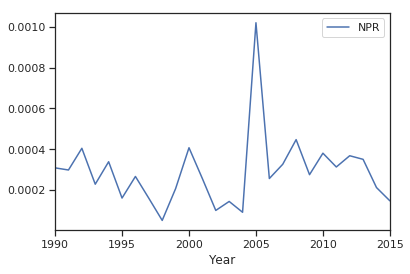

In [285]:
pubmed_gdb_citation[pubmed_gdb_citation["id"]==37].plot(x="Year", y="NPR")

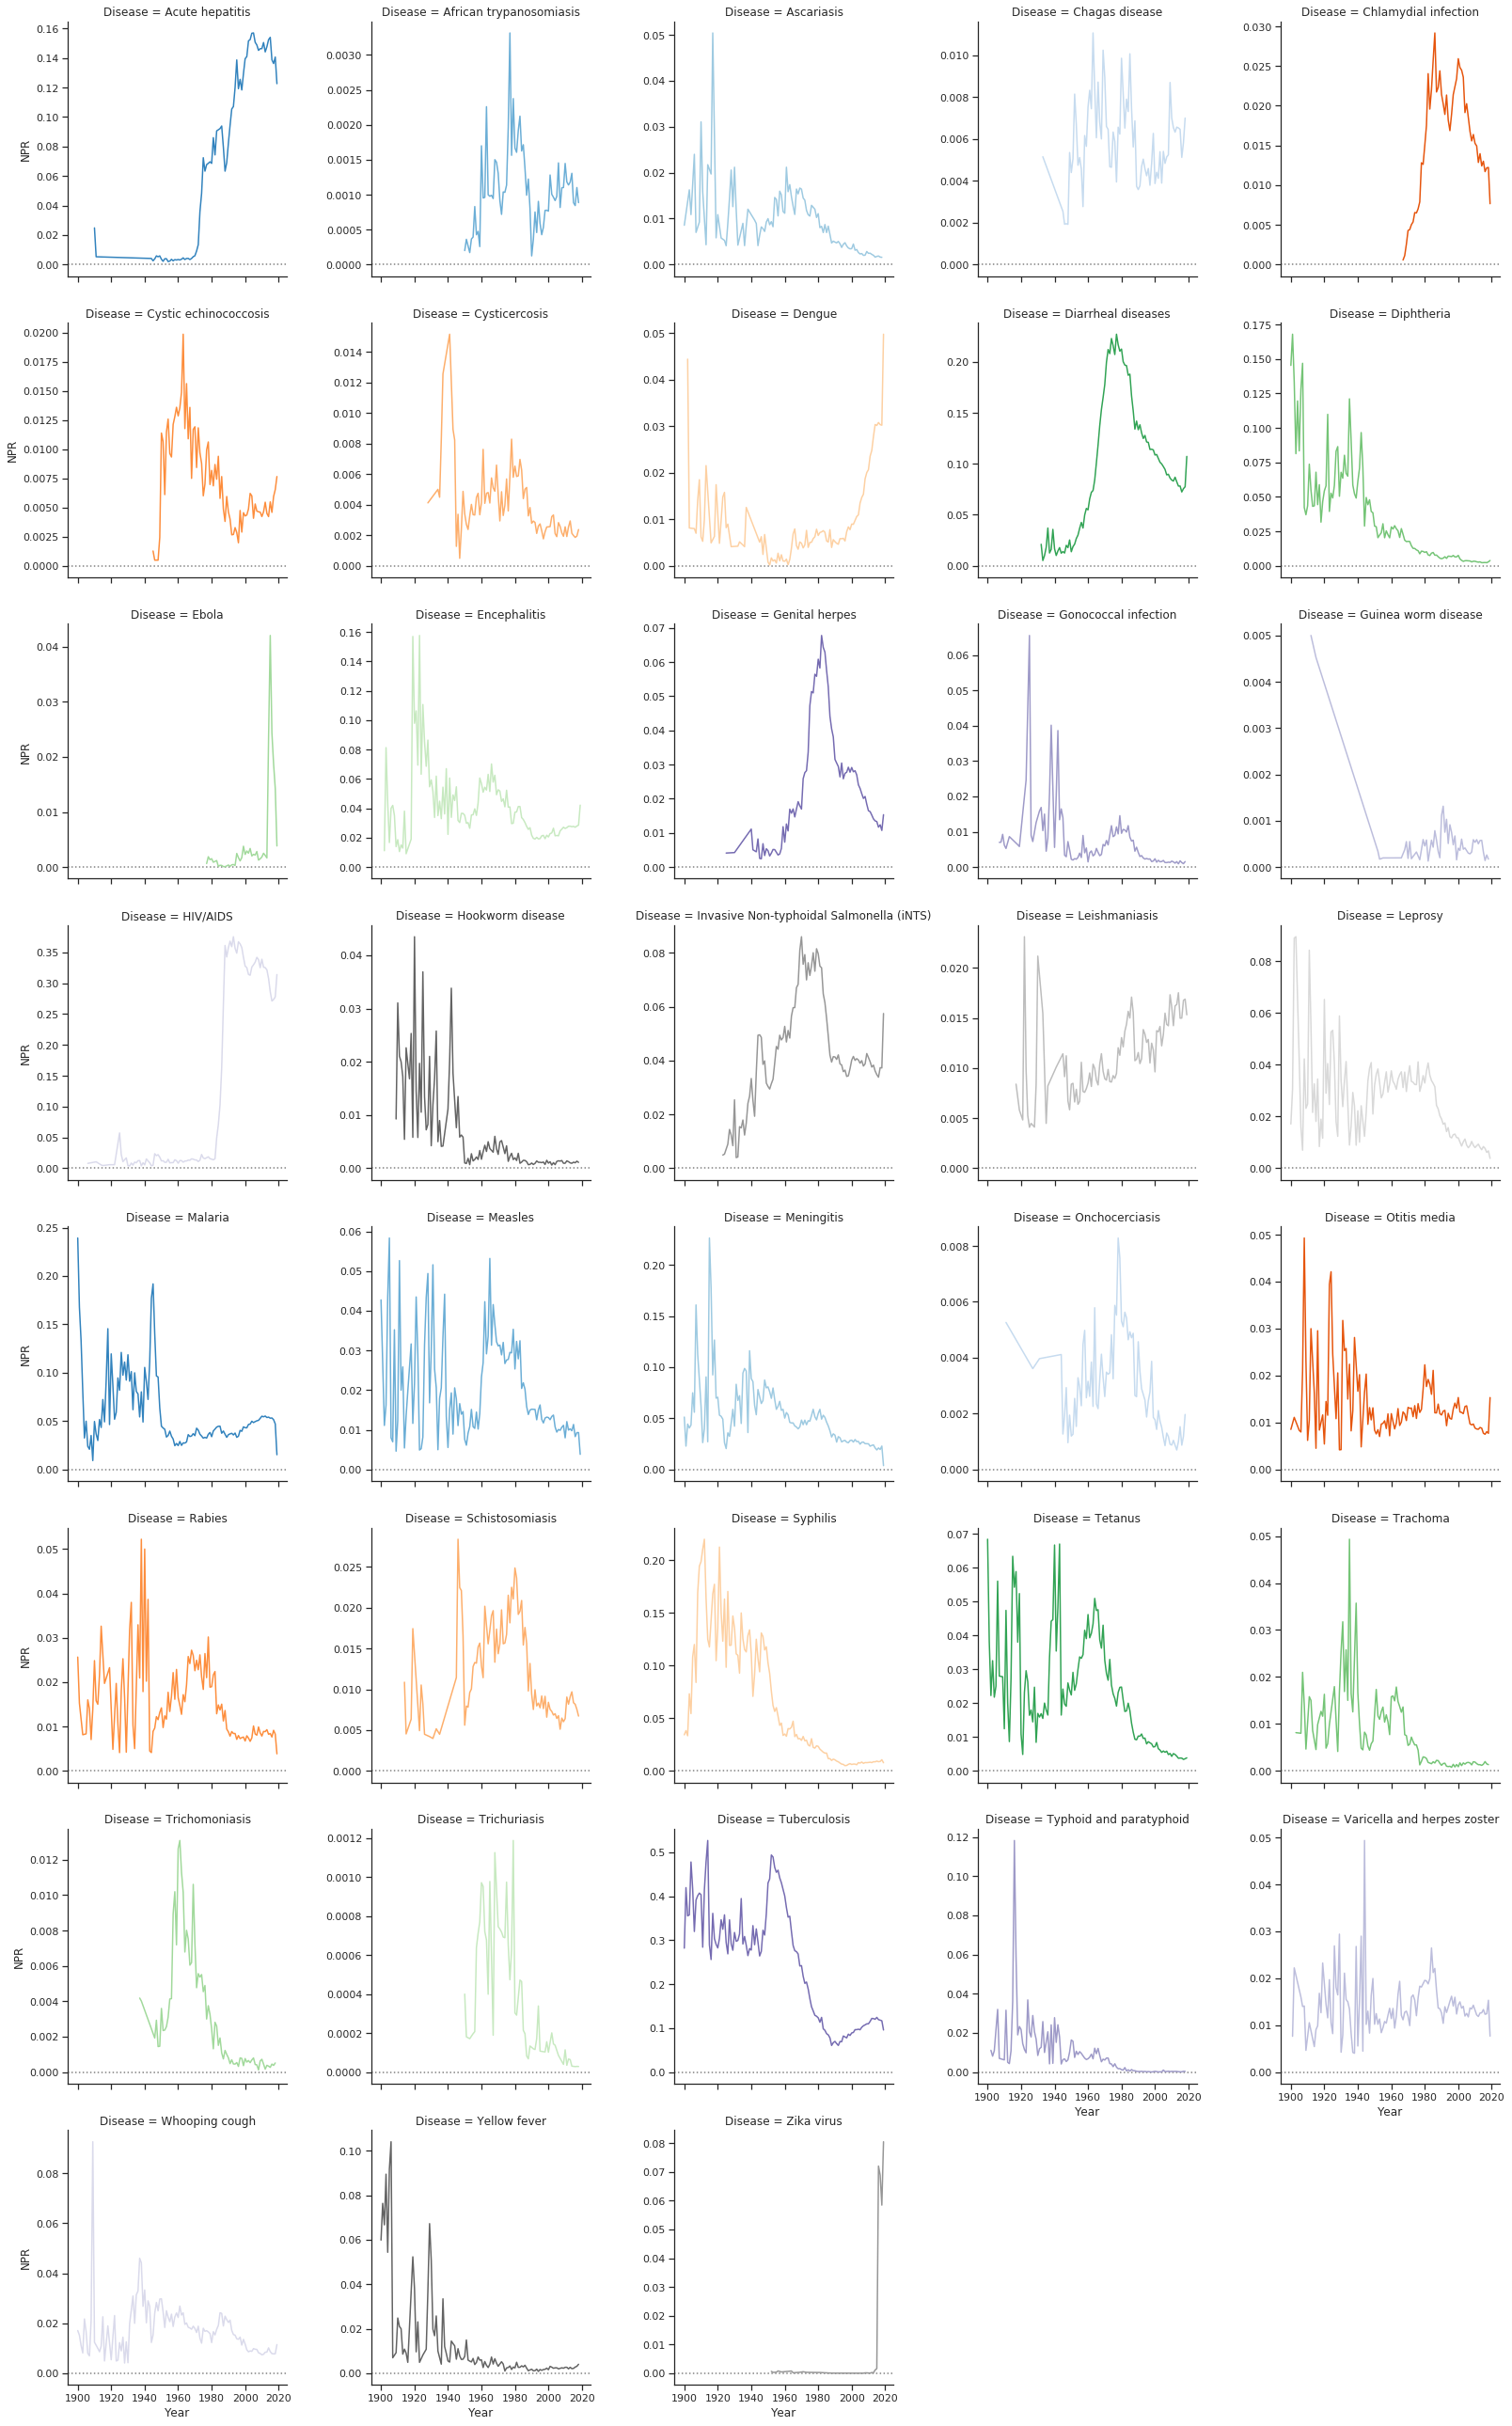

In [94]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(diseases_pub_count[diseases_pub_count["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 ,sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NPR")

# Adjust the tick positions and labels
# grid.set(xlim=(1900, 2018))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [380]:
diseases_pub_count = diseases_pub_count.sort_values(["Disease", "Year"])

In [381]:
diseases_pub_count_smooth= diseases_pub_count[["Disease","Number of papers_x","Number of papers_y"]].groupby("Disease").rolling(5).sum()

In [385]:
diseases_pub_count_smooth = diseases_pub_count_smooth.reset_index()

In [388]:
diseases_pub_count_smooth["Year"] = diseases_pub_count["Year"].values

In [390]:
diseases_pub_count_smooth["NPR"] = diseases_pub_count_smooth["Number of papers_x"]/diseases_pub_count_smooth["Number of papers_y"]

In [391]:
diseases_pub_count_smooth = diseases_pub_count_smooth.sort_values(["Disease", "Year"])

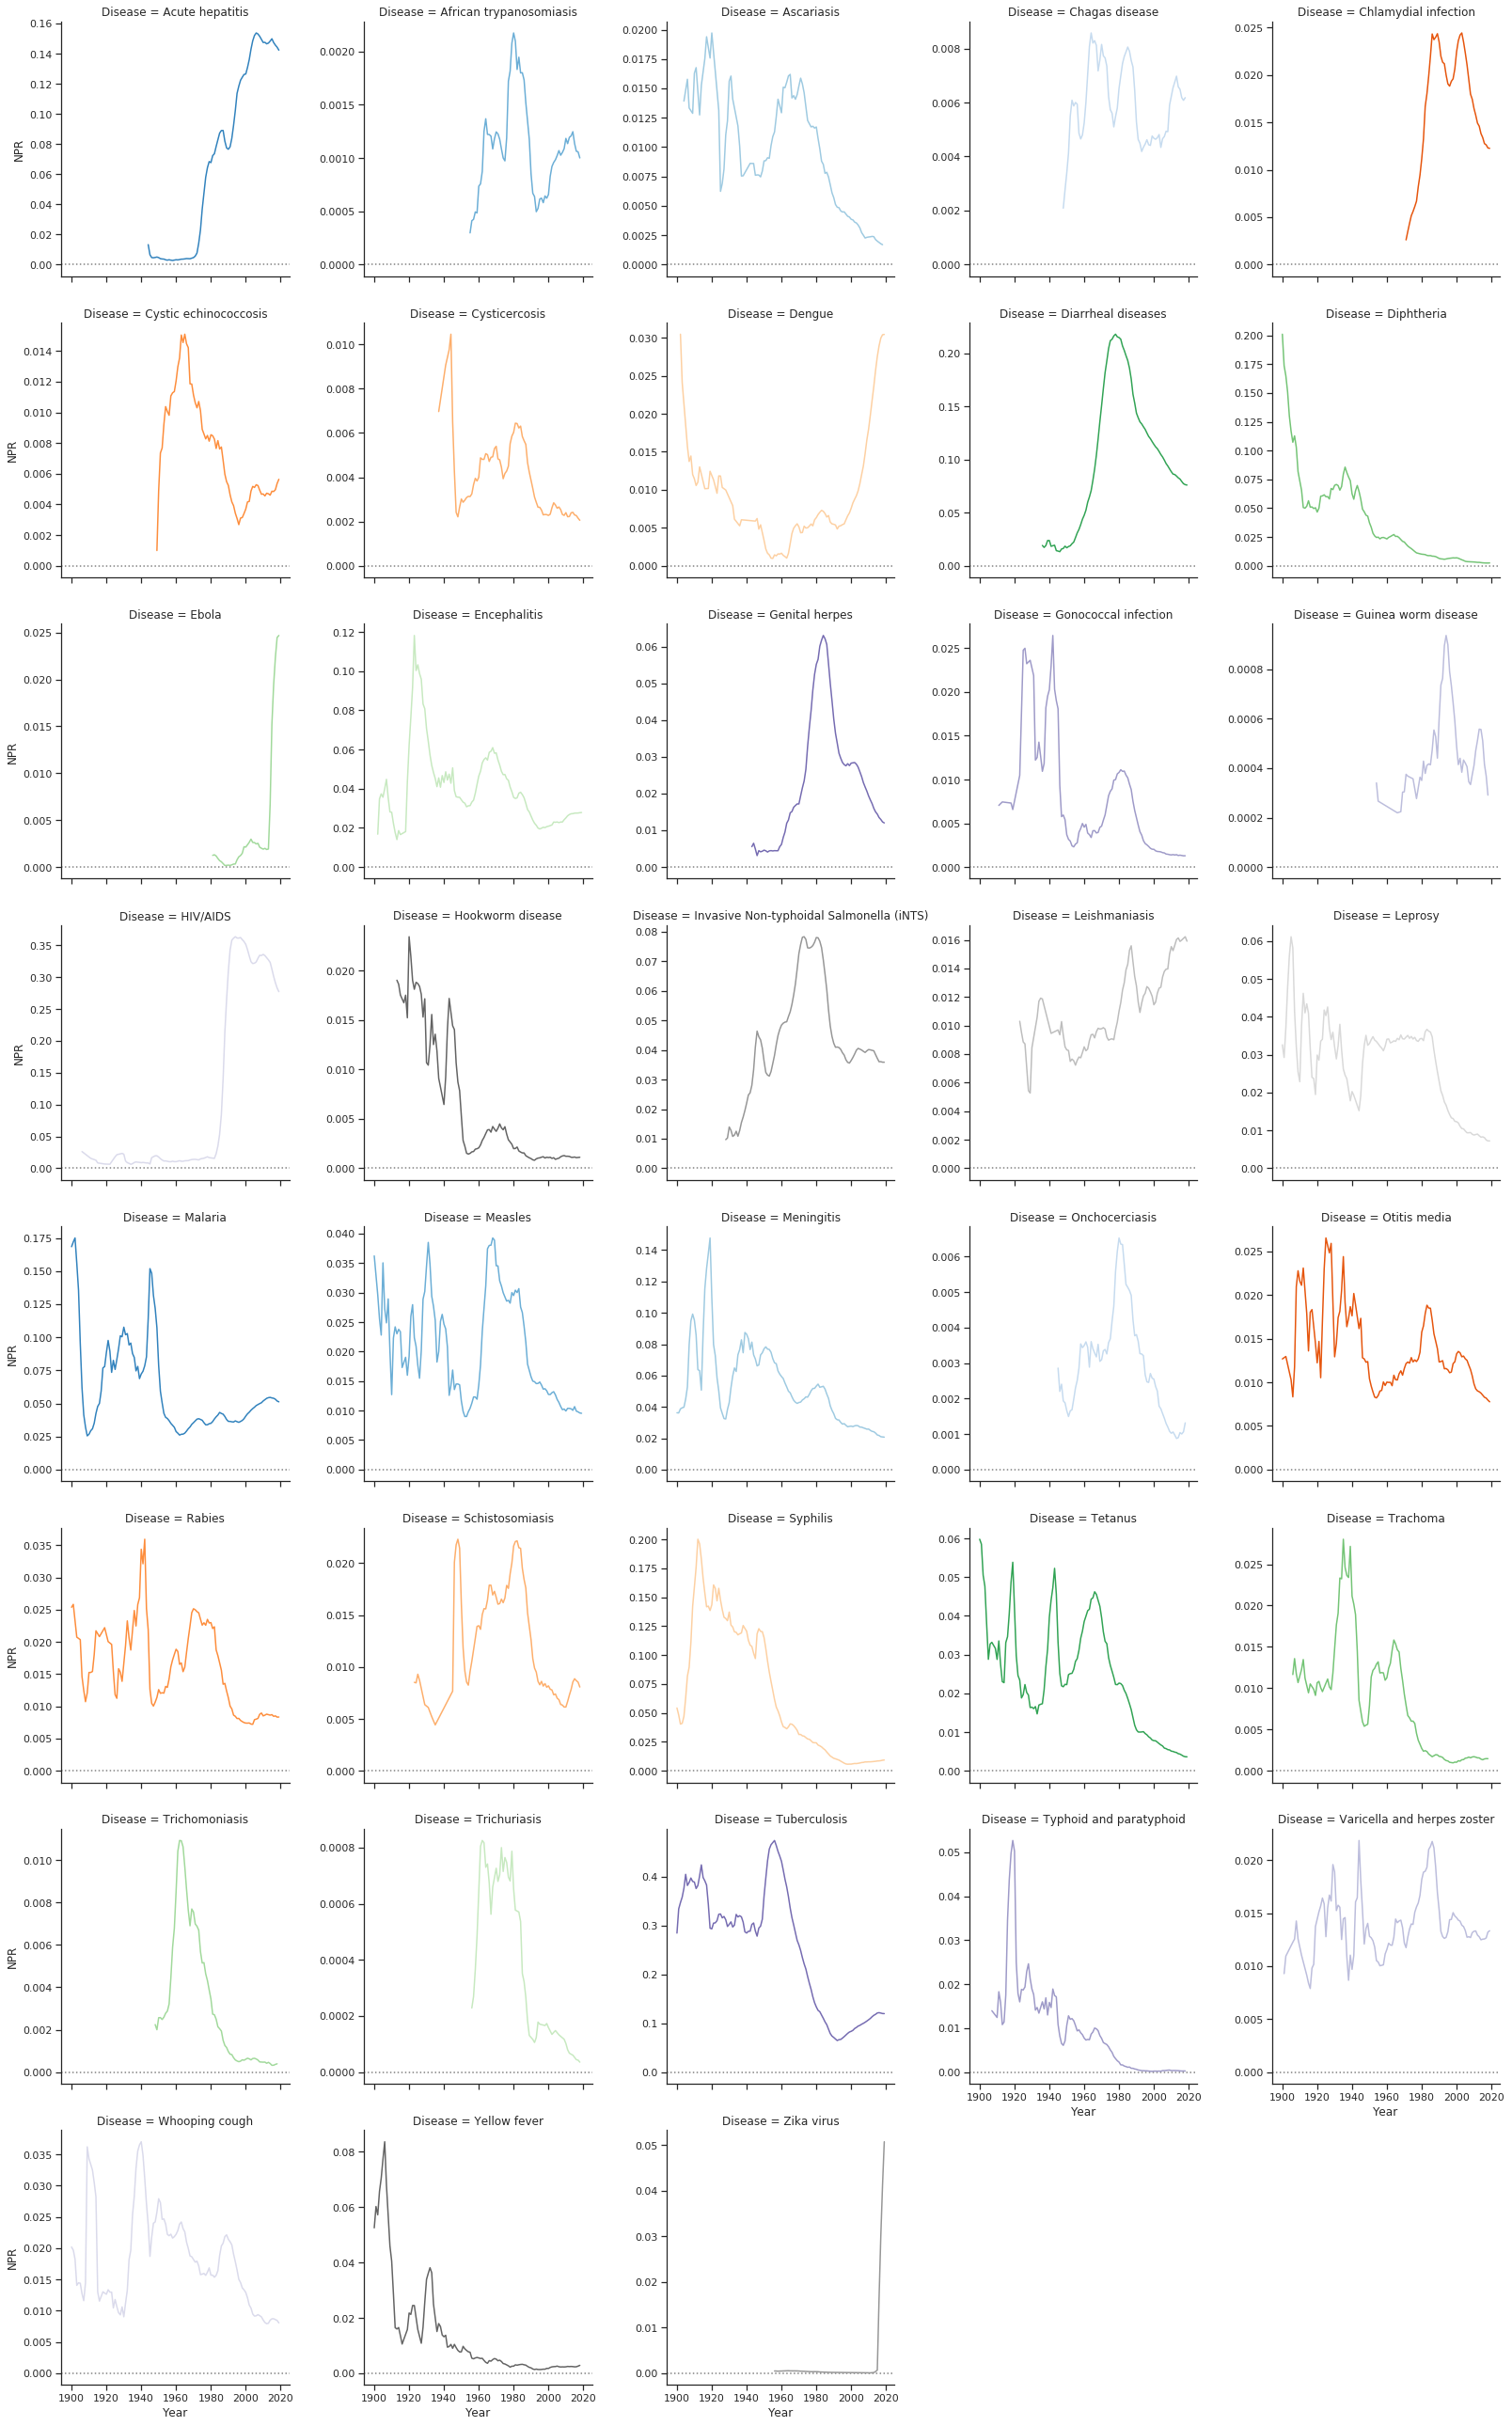

In [392]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(diseases_pub_count_smooth[diseases_pub_count_smooth["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 ,sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NPR")

# Adjust the tick positions and labels
# grid.set(xlim=(1900, 2018))

# Adjust the arrangement of the plots


#### NCR

In [190]:
disease_citations = disease_citations.rename({"disease":"Disease"})


In [191]:
# disease_citations = disease_citations.rename({"year":"Year","Citations Norm":"NCR", "disease":"Disease"})
# disease_citations = disease_citations.join(disease_names, {"id":"id"})
disease_citations = disease_citations.sort(["Disease", "Year"])

AttributeError: 'DataFrame' object has no attribute 'sort'

In [188]:
disease_citations = disease_citations.to_dataframe()

In [304]:
disease_citations = disease_citations[disease_citations["Year"].notna()]

In [305]:
disease_citations = disease_citations[disease_citations["Year"]<2017]

In [306]:
disease_citations = disease_citations.reset_index()

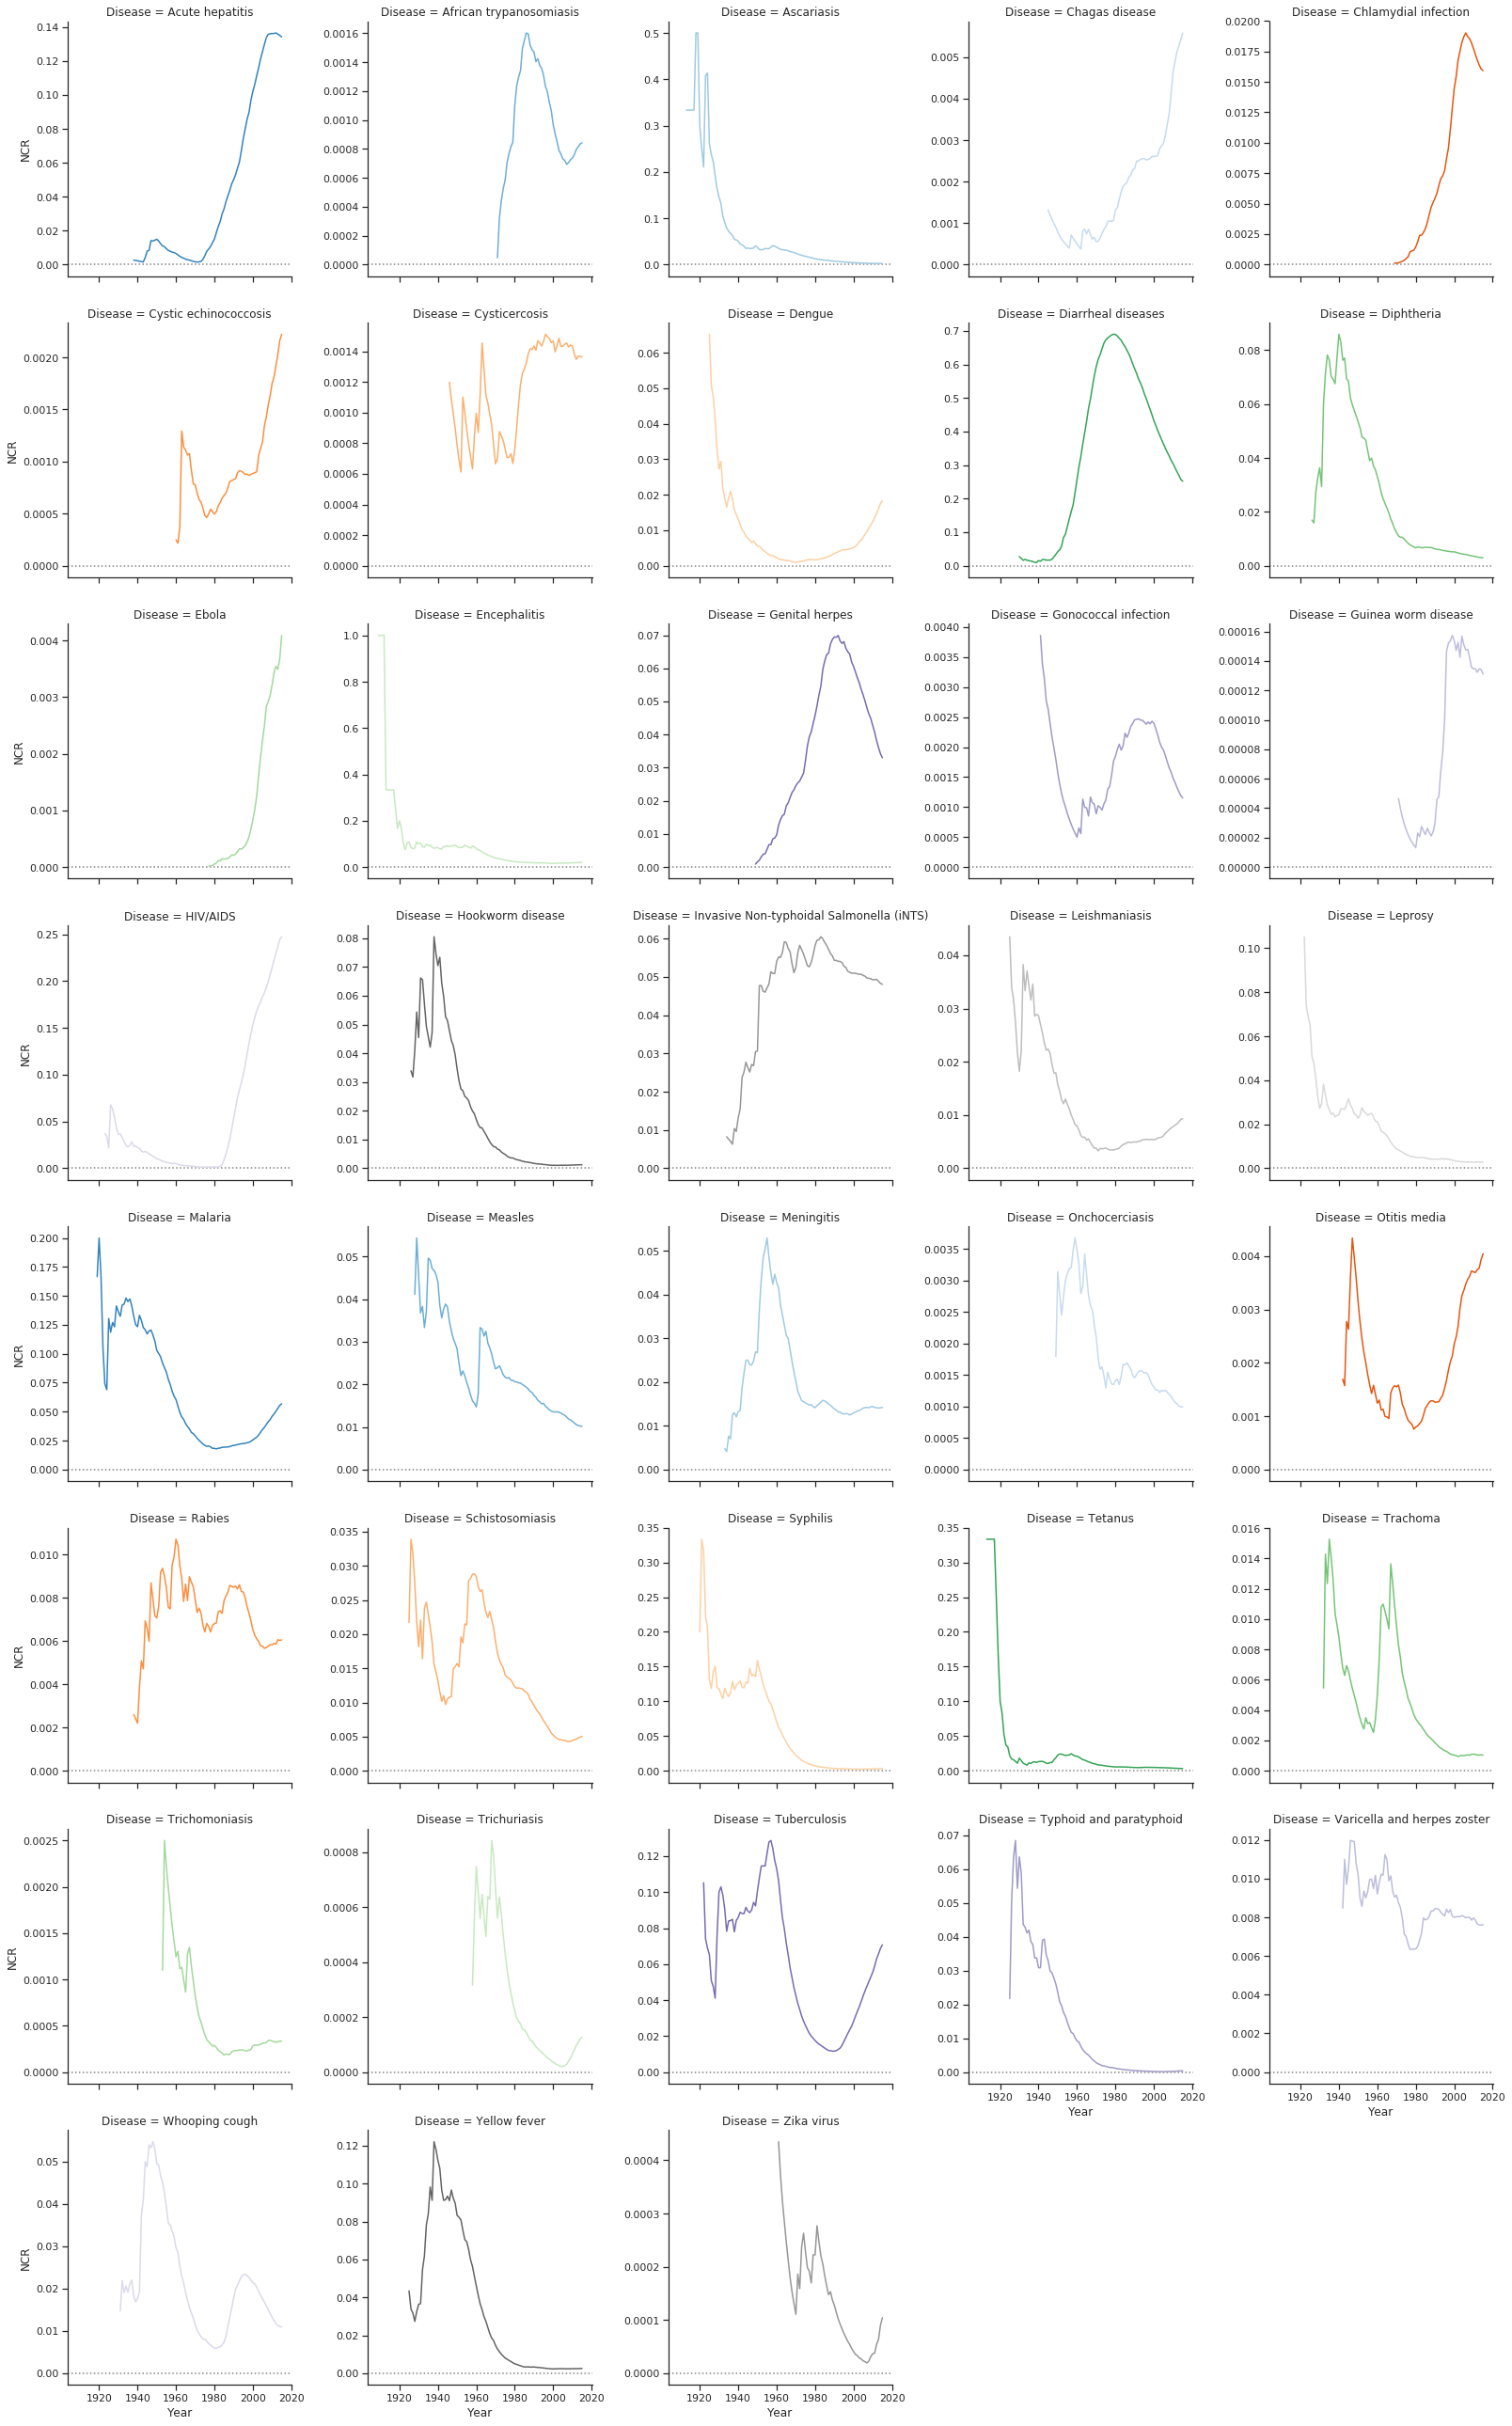

In [343]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(disease_citations[disease_citations["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NCR")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [307]:
disease_citations_smooth= disease_citations[["Disease","Citations","Total Citations"]].groupby("Disease").rolling(5).sum()

In [308]:
disease_citations_smooth = disease_citations_smooth.reset_index()

In [309]:
disease_citations_smooth["Year"] = disease_citations["Year"]

In [310]:
disease_citations_smooth["NCR"] = disease_citations_smooth["Citations"]/disease_citations_smooth["Total Citations"]

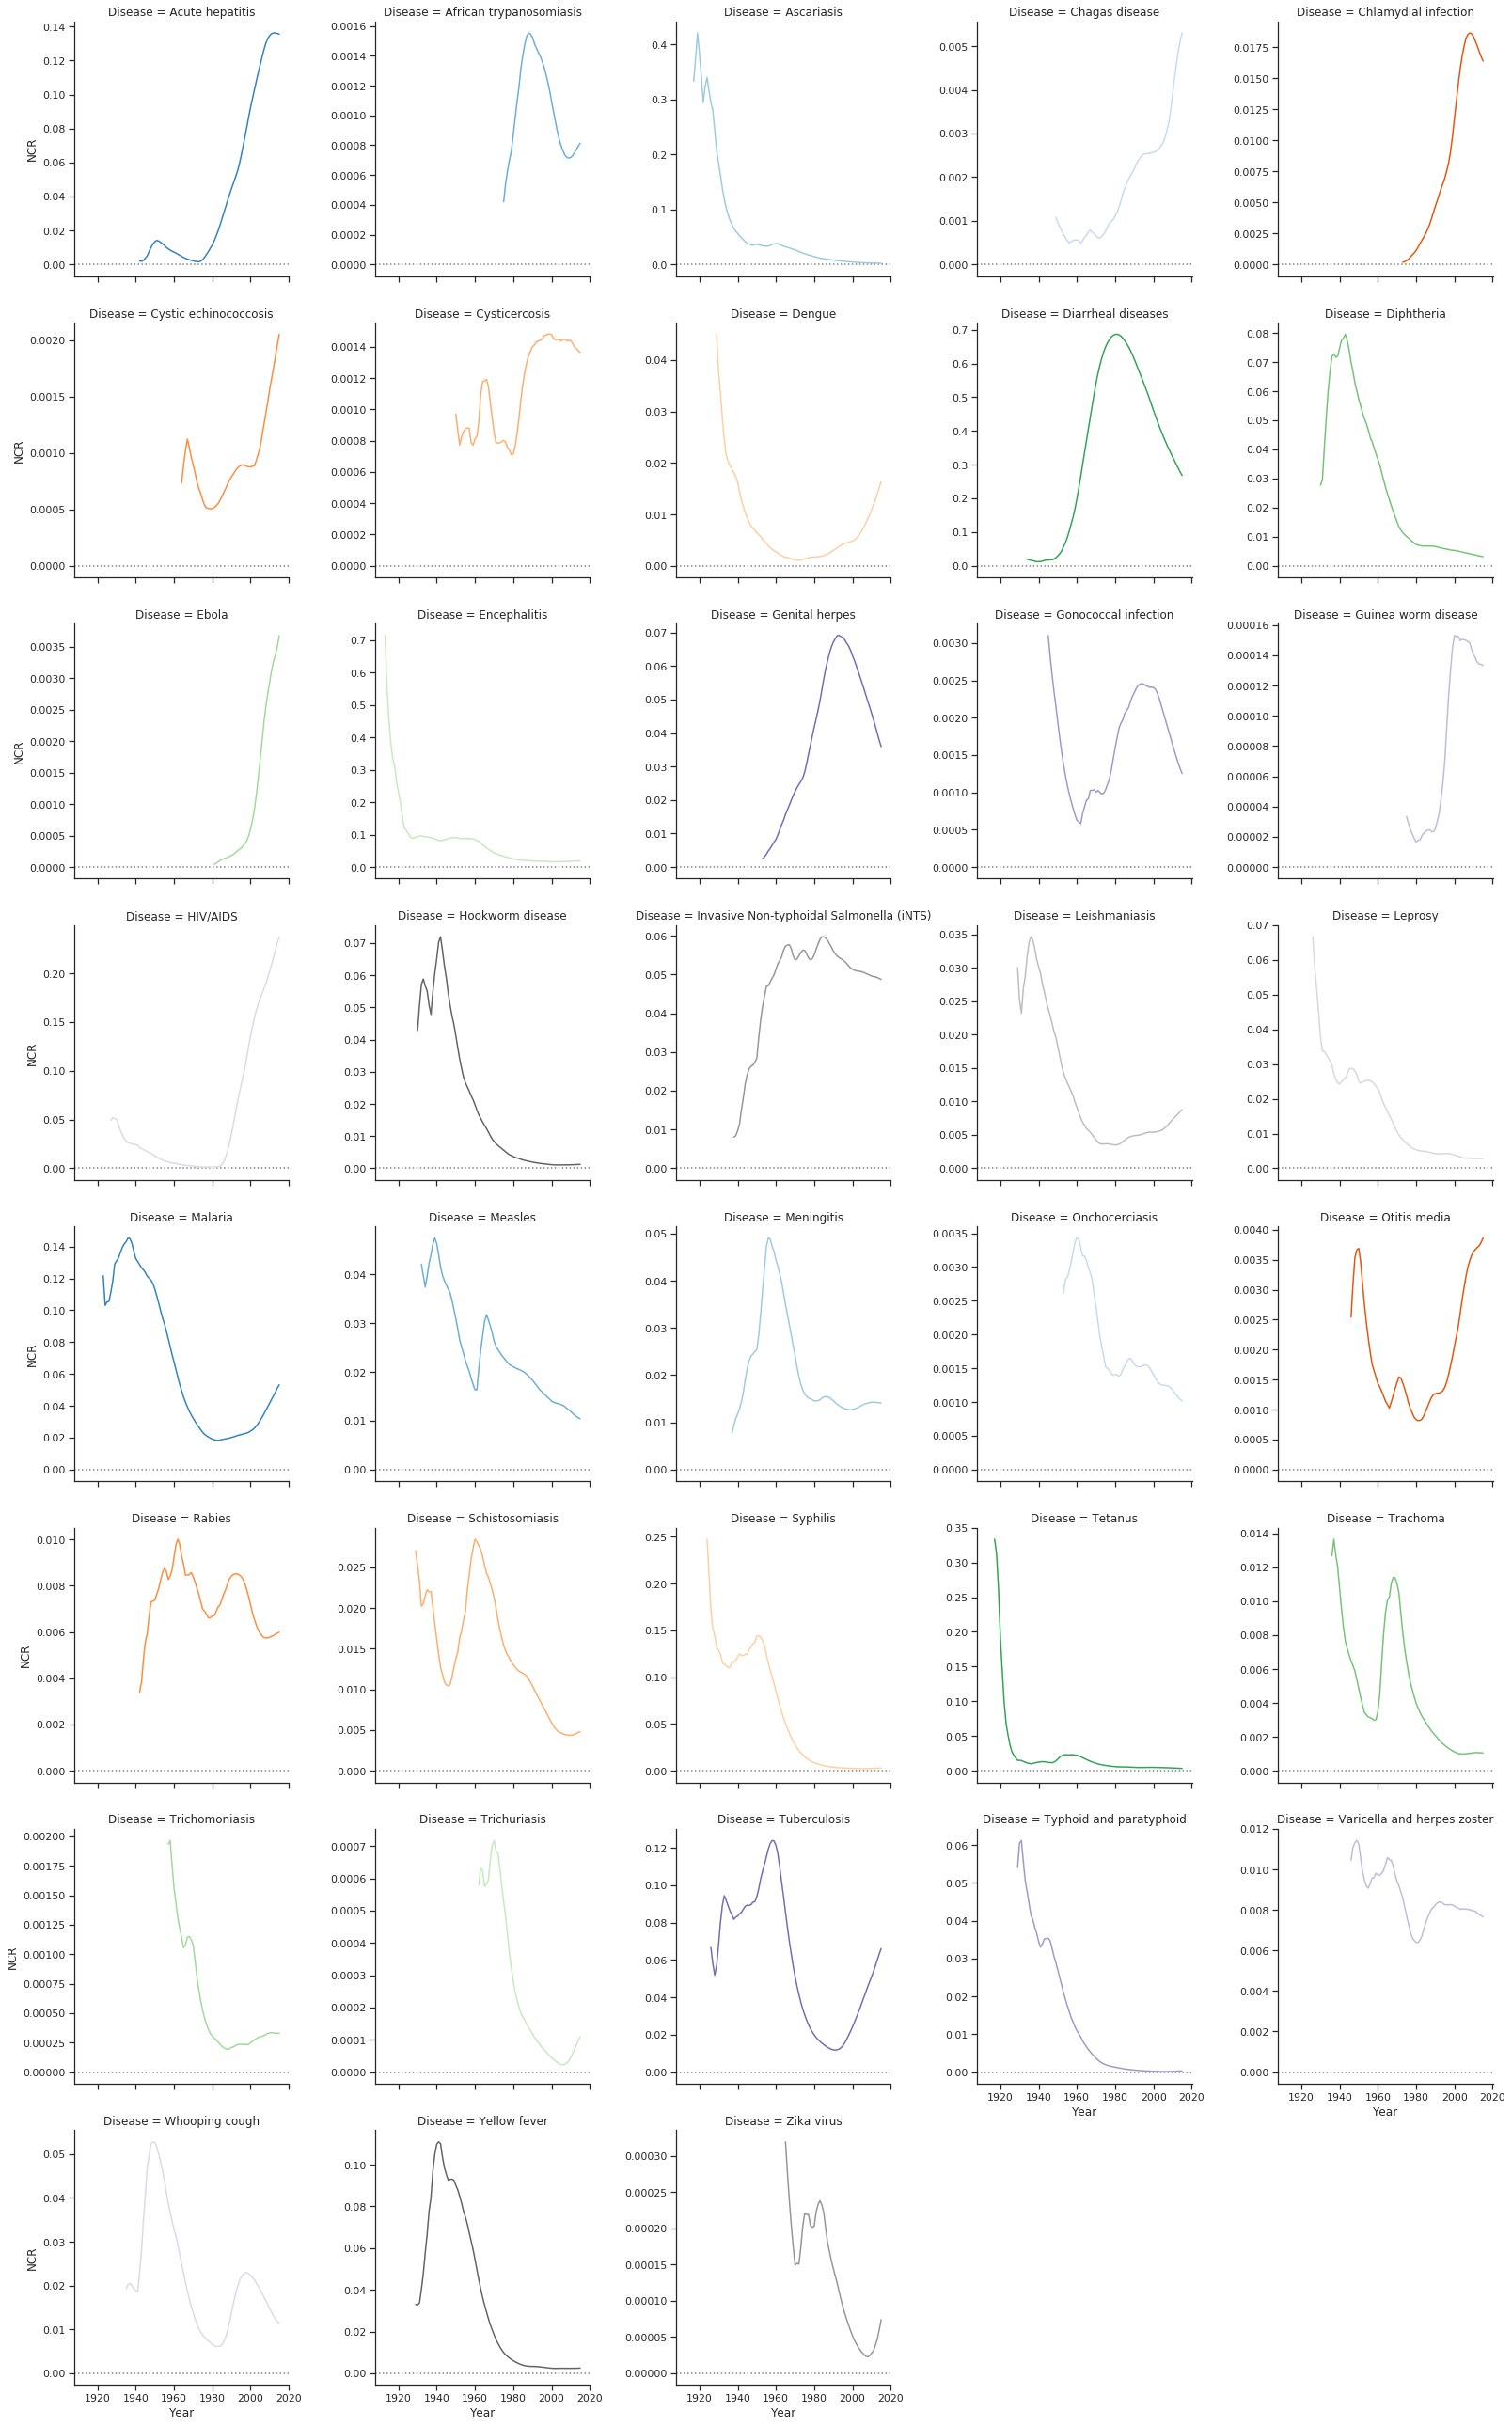

In [311]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(disease_citations_smooth[disease_citations_smooth["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NCR")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

#### Citations/DALYs

In [313]:
pubmed_gdb_citation["Citation/DALYs"] = pubmed_gdb_citation["Citations"] /pubmed_gdb_citation["val"]

In [314]:
citation_daly = pubmed_gdb_citation.rename({"year":"Year"})
citation_daly = citation_daly.sort_values(["Disease", "Year"])

In [315]:
citation_daly = citation_daly[citation_daly["val"] > 0]

In [401]:
citation_daly[citation_daly["Disease"]=="Diarrheal diseases"]

,id,Year,Number of papers_x,cause,metric,val,val_Deaths,Number of papers_y,NPR,Citations,Total Citations,NCR,Disease,Citation/DALYs,Citation/DALYs-log
732,6,1990,2160,diarrheal diseases,Rate,3311.936438,47.792985,16180,0.133498,137454.0,234233.0,0.586826,Diarrheal diseases,41.502608,3.725756
192,6,1991,2316,diarrheal diseases,Rate,3216.586615,46.718171,16746,0.138302,149918.0,261543.0,0.573206,Diarrheal diseases,46.607792,3.841768
629,6,1992,2255,diarrheal diseases,Rate,3082.256108,45.148800,17292,0.130407,163074.0,292816.0,0.556916,Diarrheal diseases,52.907349,3.968542
478,6,1993,2182,diarrheal diseases,Rate,2967.046487,43.677116,17469,0.124907,176194.0,323296.0,0.544993,Diarrheal diseases,59.383633,4.084019
371,6,1994,2263,diarrheal diseases,Rate,2860.093375,42.251506,17698,0.127868,190728.0,359146.0,0.531060,Diarrheal diseases,66.685935,4.199994
104,6,1995,2261,diarrheal diseases,Rate,2748.645544,40.824683,18615,0.121461,205431.0,400307.0,0.513184,Diarrheal diseases,74.738993,4.314002
863,6,1996,2268,diarrheal diseases,Rate,2619.562104,39.208237,18734,0.121063,221337.0,443968.0,0.498543,Diarrheal diseases,84.493893,4.436679
101,6,1997,2138,diarrheal diseases,Rate,2509.130641,37.957329,18733,0.114130,240831.0,499384.0,0.482256,Diarrheal diseases,95.981850,4.564159
316,6,1998,2214,diarrheal diseases,Rate,2416.285773,36.851092,19369,0.114306,267217.0,573042.0,0.466313,Diarrheal diseases,110.589982,4.705830
90,6,1999,2195,diarrheal diseases,Rate,2316.319081,35.607723,19303,0.113713,297627.0,661126.0,0.450182,Diarrheal diseases,128.491365,4.855862


In [341]:
citation_daly["Citation/DALYs-log"] = np.log(citation_daly["Citation/DALYs"])

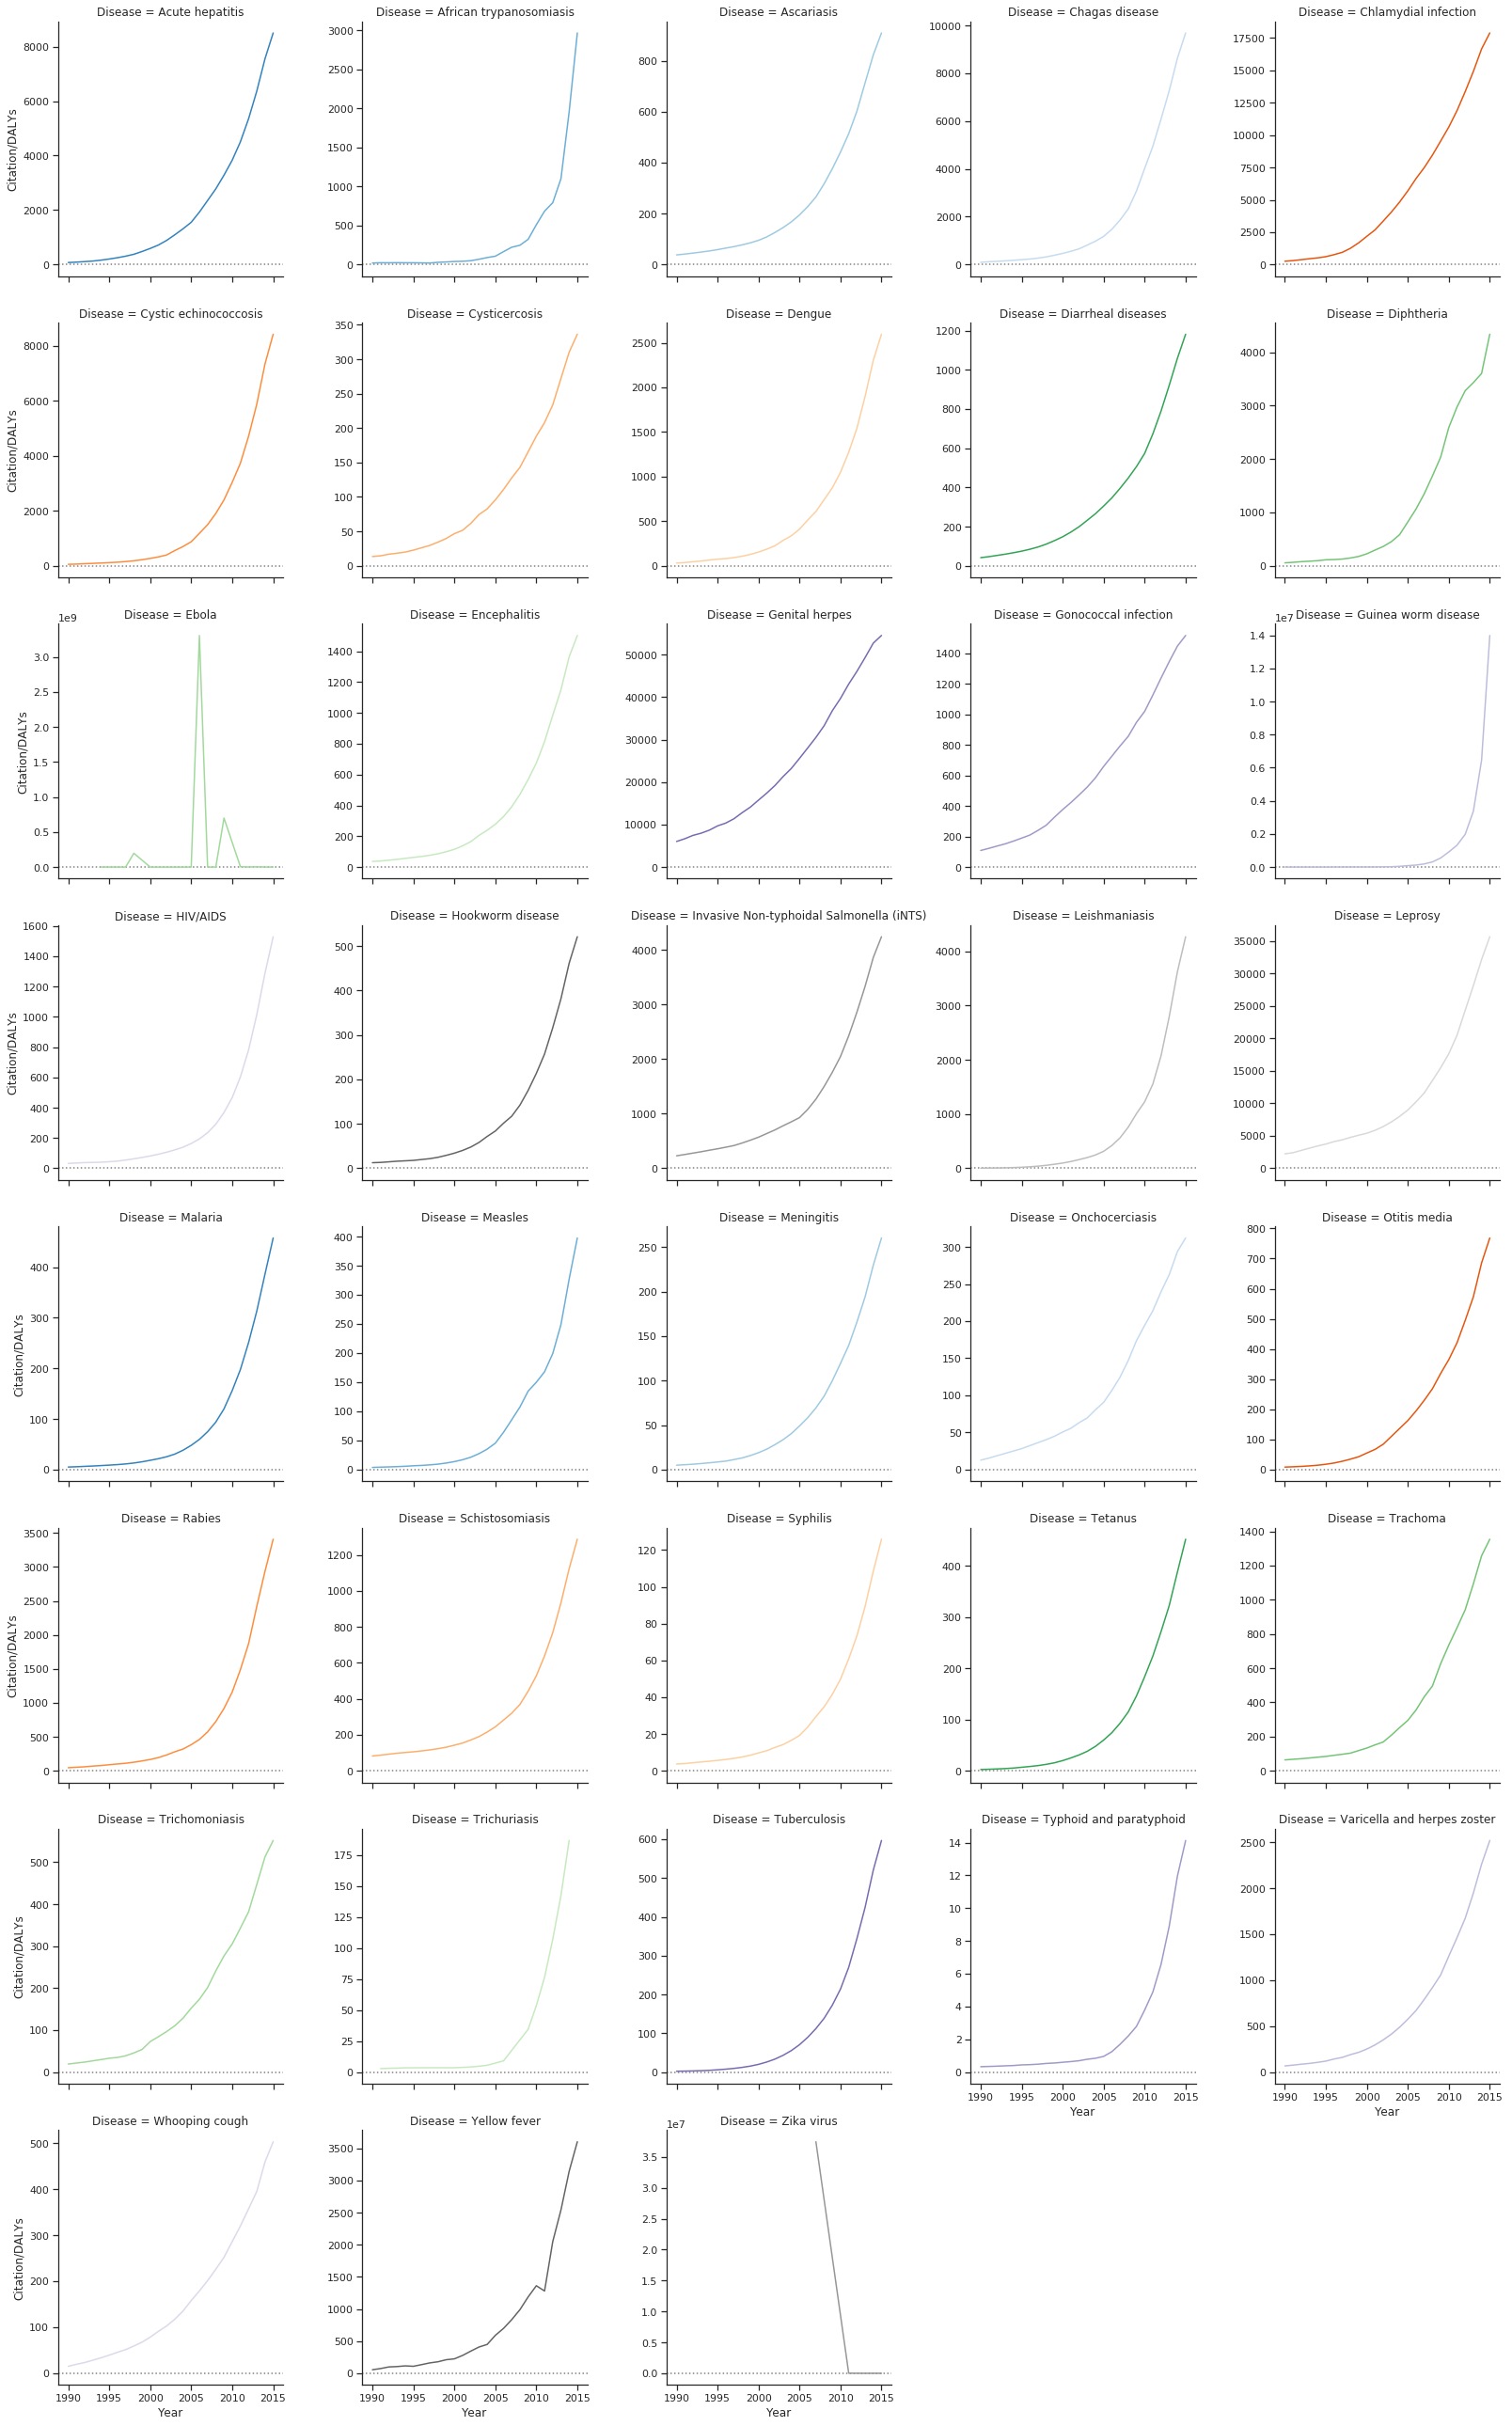

In [394]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(citation_daly[citation_daly["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "Citation/DALYs")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

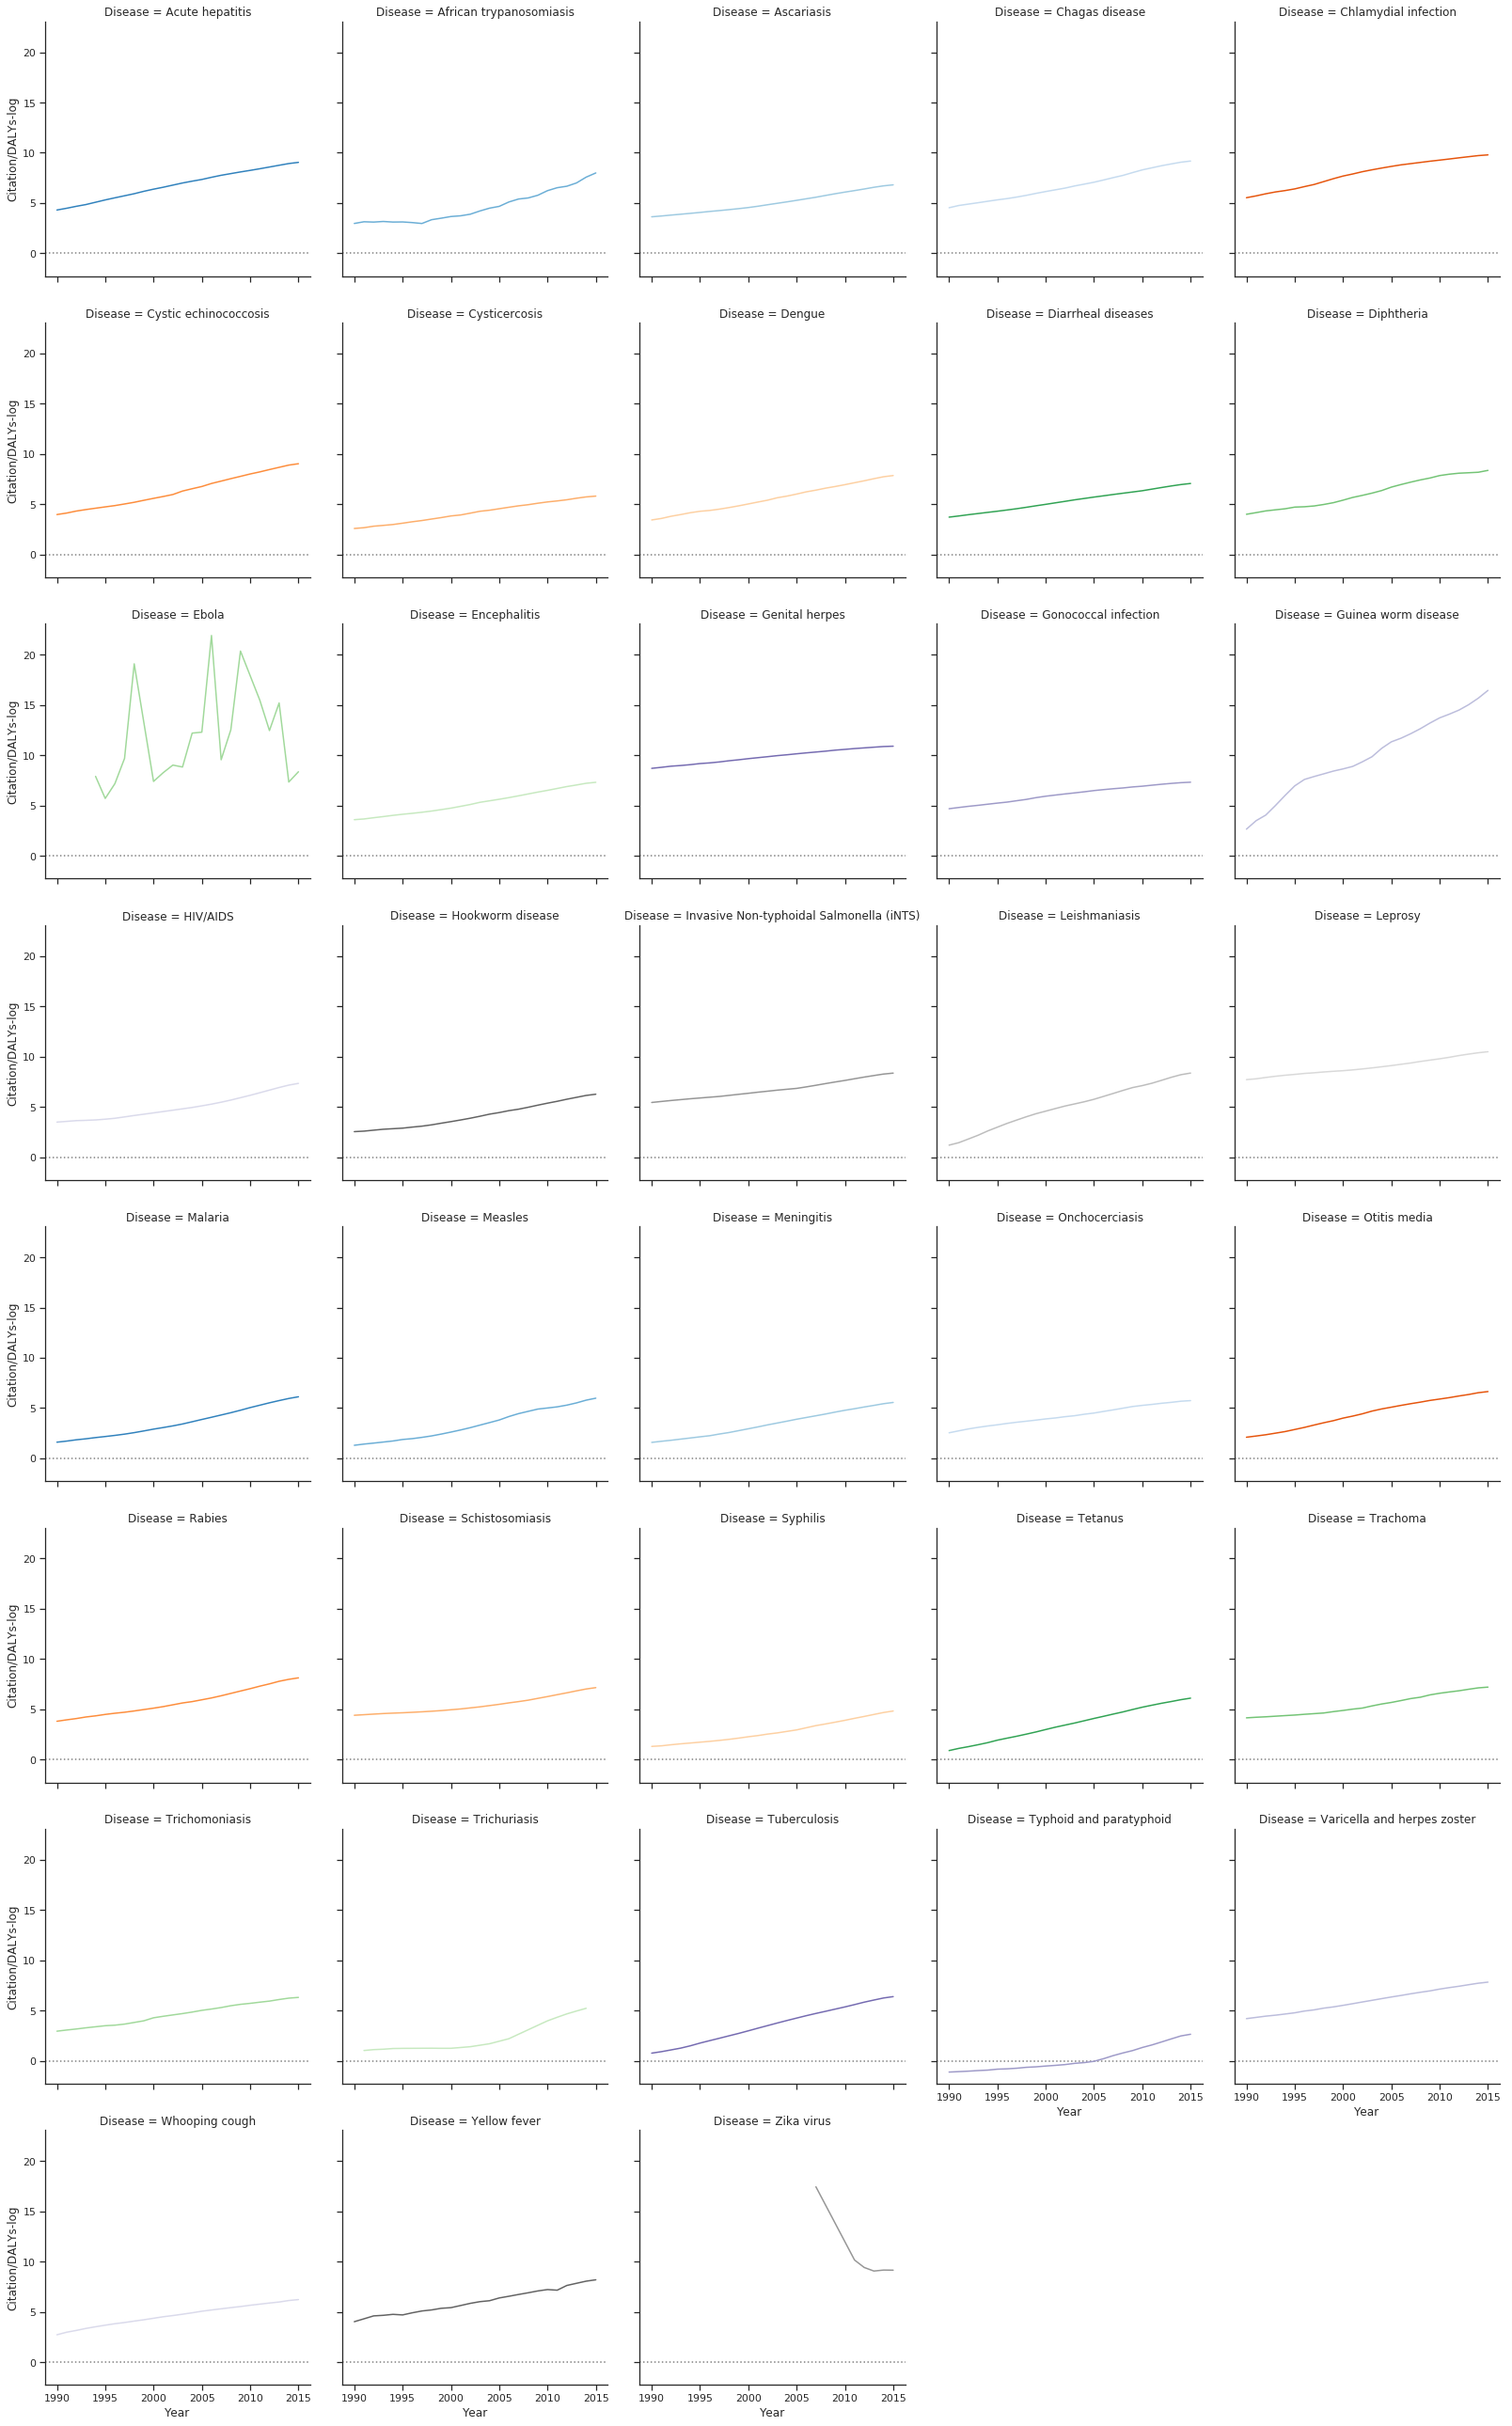

In [342]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(citation_daly[citation_daly["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=True)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "Citation/DALYs-log")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

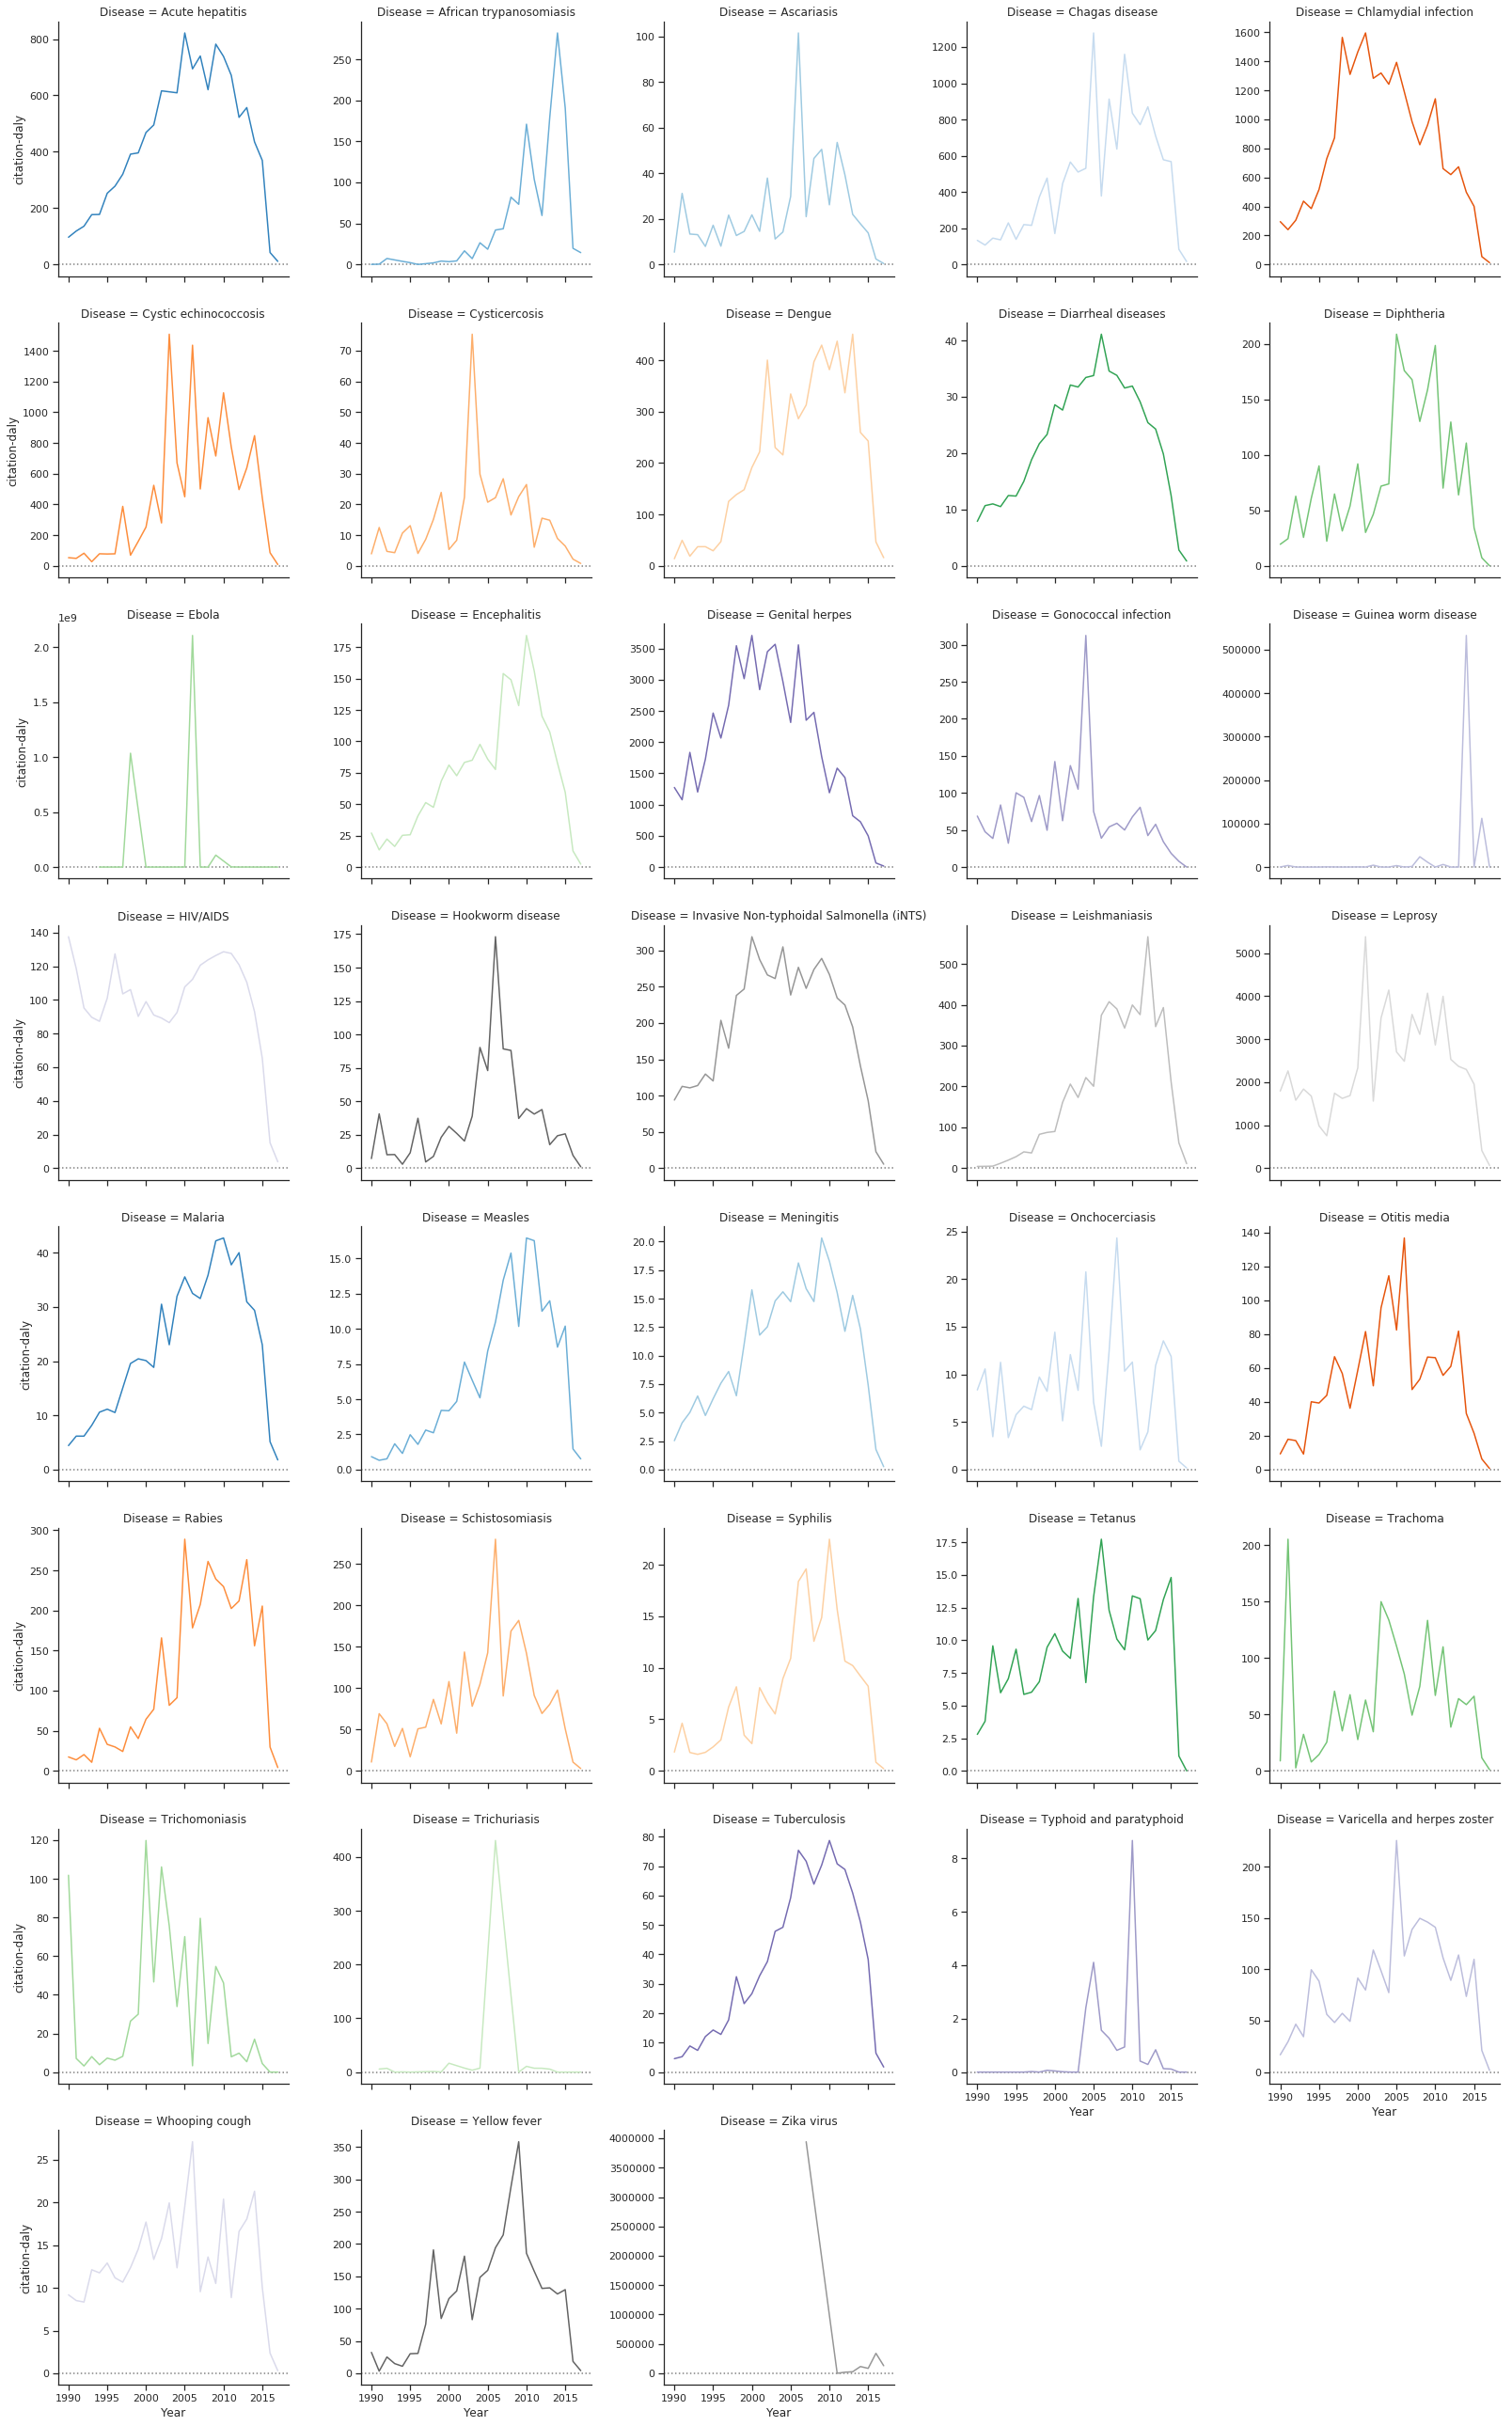

In [148]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(citation_daly[citation_daly["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "citation-daly")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

,id,Year,Number of papers_x,cause,metric,val,val_Deaths,Number of papers_y,NPR,Citations,Total Citations,NCR,Disease,citation-daly
954,36,1990,1331,acute hepatitis,Rate,157.744506,2.722668e+00,16180,0.082262,15268.0,133181.0,0.114641,Acute hepatitis,9.678942e+01
955,36,1991,1579,acute hepatitis,Rate,156.667007,2.709583e+00,16746,0.094291,18613.0,158499.0,0.117433,Acute hepatitis,1.188061e+02
956,36,1992,1823,acute hepatitis,Rate,154.865608,2.688581e+00,17292,0.105424,21065.0,164994.0,0.127671,Acute hepatitis,1.360212e+02
957,36,1993,1871,acute hepatitis,Rate,152.640338,2.661595e+00,17469,0.107104,27024.0,173725.0,0.155556,Acute hepatitis,1.770436e+02
958,36,1994,2124,acute hepatitis,Rate,149.181443,2.618175e+00,17698,0.120014,26509.0,200852.0,0.131983,Acute hepatitis,1.776964e+02
959,36,1995,2582,acute hepatitis,Rate,146.232244,2.581607e+00,18615,0.138705,36985.0,239852.0,0.154199,Acute hepatitis,2.529196e+02
960,36,1996,2233,acute hepatitis,Rate,141.841966,2.527227e+00,18734,0.119195,39445.0,287357.0,0.137268,Acute hepatitis,2.780912e+02
961,36,1997,2352,acute hepatitis,Rate,139.433800,2.506556e+00,18733,0.125554,44666.0,302609.0,0.147603,Acute hepatitis,3.203384e+02
962,36,1998,2292,acute hepatitis,Rate,136.641296,2.475204e+00,19369,0.118333,53510.0,366243.0,0.146105,Acute hepatitis,3.916093e+02
963,36,1999,2497,acute hepatitis,Rate,133.889070,2.438440e+00,19303,0.129358,53038.0,352893.0,0.150295,Acute hepatitis,3.961339e+02


#### Corrolation

In [327]:

def get_lags(cc):
    """
    Return array with lags

    :param cc: Cross-correlation returned by correlate_maxlag.
    :return: lags
    """
    mid = (len(cc) - 1) / 2
    if len(cc) % 2 == 1:
        mid = int(mid)
    return np.arange(len(cc)) - mid

def normolized_cross_corr(a, b):
    a = (a - np.mean(a)) / (np.std(a) * len(a))
    b = (b - np.mean(b)) / (np.std(b))
    c = np.correlate(a, b, 'full')
    xcorr = SFrame()
    xcorr["shift"] = get_lags(c)
    xcorr["corr"] = c
    return xcorr

In [328]:
def get_diseases_cross_corr(diseases_id, corr, corr_fileds):
    res =SFrame()
    for title, data in tqdm(get_d(corr, diseases_id)):
#         print(title)
#         data = data[data["year"]<2019]
        values = data[corr_fileds[0]]
        num = data[corr_fileds[1]]
#         num_5 = data["Number of papers (Ref >5)"]
        corr = normolized_cross_corr(values, num)
#         print(corr[corr["shift"]==0])
        corr["diseases"]= [title]*len(corr)
#         corr2 = normolized_cross_corr(values, num_5)
#         corr["corr_5"] = corr2["corr"]
        res = res.append(corr)
    return res
    

In [325]:
dff_corr =  pubmed_gdb.merge(disease_citations,left_on=["id", "year"], right_on=["id", "Year"])

In [333]:
corr_npr = get_diseases_cross_corr(disease_names, dff_corr,("val", "Normalized Number of papers"))
corr_papers = get_diseases_cross_corr(disease_names, dff_corr,("val", "Number of papers_x"))
corr_cnr = get_diseases_cross_corr(disease_names, dff_corr,("val", "NCR"))
corr_citations = get_diseases_cross_corr(disease_names, dff_corr,("val", "Citations"))

In [335]:
def get_best_corr(res, suffixes):
    return res[(res['shift']<=0)&(res['shift']>-5)].groupby("diseases", operations={f"max_shift_corr_{suffixes}": agg.ARGMAX("corr","shift"),f"max_corr_{suffixes}": agg.ARGMAX("corr","corr"),
                                   f"min_shift_corr_{suffixes}": agg.ARGMIN("corr","shift"),f"min_corr_{suffixes}": agg.ARGMIN("corr","corr")})

In [336]:
corr = get_best_corr(corr_npr,"NPR").join(get_best_corr(corr_papers, "Papers"), on={"diseases":"diseases"}).join(get_best_corr(corr_cnr, "CNR"), on={"diseases":"diseases"}).join(get_best_corr(corr_citations, "Citations"), on={"diseases":"diseases"})

In [337]:
corr.save("output/corr2.csv", "csv")

In [156]:
pubmed_gdb.head(2)

,id,year,Number of papers_x,cause,metric,val,val_DALYs,Number of papers_y,Number of papers,Normalized Number of papers
2,18,1990,169,syphilis,Rate,2.482625,215.058343,15222,15222,0.011102
5,19,1990,347,chlamydial infection,Rate,0.022875,5.043920,15222,15222,0.022796


In [194]:
res = get_diseases_cross_corr(diseases_id, pubmed_gdb,("val", "Number of papers_x"))

In [195]:
best_corr = res[(res['shift']<=0)&(res['shift']>-5)].groupby("diseases", operations={"max_shift_corr": agg.ARGMAX("corr","shift"),"max_corr": agg.ARGMAX("corr","corr"),
                                   "min_shift_corr": agg.ARGMIN("corr","shift"),"min_corr": agg.ARGMIN("corr","corr")})

In [196]:
best_corr.sort("min_corr")

diseases,max_shift_corr,max_corr,min_shift_corr,min_corr
36: Hepatitis B,-4,-0.5489492898733306,0,-0.9833112334347448
27: Tuberculosis,-4,-0.6506982280896545,0,-0.9751966331002979
31: Encephalitis,-4,-0.7160376487668838,0,-0.9460447765070261
33: Varicella And HerpesZoster ...,-4,-0.5385472209568446,0,-0.9010380794946572
22: Meningitis,-4,-0.6640729989478517,0,-0.8960126669429479
21: Rabies,-4,-0.6923911283331452,0,-0.8951571096300697
23: Cystic Echinococcosis,-4,-0.6492277617074927,0,-0.8838551922548883
18: Syphilis,-4,-0.7343071184736405,0,-0.8833257266140158
8: AfricanTrypanosomiasis ...,-4,-0.4642394425794624,0,-0.840576951254568
0: Chagas Disease,-4,-0.6763581660491724,0,-0.8335930391537093


In [199]:
best_corr.sort("max_corr",False).print_rows(30)

+-------------------------------+----------------+---------------------+----------------+
|            diseases           | max_shift_corr |       max_corr      | min_shift_corr |
+-------------------------------+----------------+---------------------+----------------+
|            3: Zikv            |       0        |  0.9972279646113171 |       -4       |
|           10: Dengue          |       0        |  0.9921895010569646 |       -4       |
|            2: Ebola           |       -1       |  0.8344253378871697 |       -4       |
|          16: Tetanus          |       0        |  0.8207777246330292 |       -4       |
|         34: Diphtheria        |       -1       |  0.7015877880971273 |       -4       |
|         15: Ascariasis        |       0        |  0.6849690290880027 |       -4       |
|         28: Salmonella        |       -4       |  0.5275979727207039 |       0        |
|            12: Hiv            |       -4       | 0.48254347592689173 |       0        |
|         

In [63]:
best_corr.save("best_corr_pubmed2.csv","csv")